# Projet Data Mining EEG - parties I a V

Ce notebook suit les cinq premieres parties du PDF : exploration (I), annotations (II), variable cible (III), segmentation (IV) et extraction de caracteristiques temporelles (V). Les fichiers `.h` ne sont jamais lus. La conversion `.mat` -> `.csv` est une etape technique necessaire avant les consignes du sujet.

**Convention des annotations (corrigee)** : dans l'Excel, `DebutTrace`, `DebCE*` et `FinCE*` sont des **heures d'horloge** `hh:mm:ss` (stockees par Excel comme fraction de jour). Exemple pour `190304A-E` : debut du trace `10:13:35`, debut de la crise 1 `10:35:06`, fin `10:35:13`, donc duree `10:35:13 - 10:35:06 = 7 s`. Le temps de crise dans le signal est `heure de crise - heure de debut du trace`.

Ordre d'execution : lancer les cellules **dans l'ordre** (Kernel > Restart & Run All).

In [1]:
from pathlib import Path
import sys
import re
import json
import warnings
import numpy as np
import pandas as pd

# Evite que le dossier local .matio_deps masque les vrais paquets du noyau Jupyter.
LOCAL_PACKAGES = Path('.matio_deps').resolve()
for entry in list(sys.path):
    try:
        if Path(entry).resolve() == LOCAL_PACKAGES:
            sys.path.remove(entry)
    except Exception:
        pass

if LOCAL_PACKAGES.exists():
    try:
        import scipy  # noqa: F401
    except Exception:
        sys.path.insert(0, str(LOCAL_PACKAGES))

try:
    from scipy.io import loadmat
except ImportError:
    loadmat = None
    print('SciPy absent : pip install scipy')

try:
    import matio as matio_reader
except ImportError:
    matio_reader = None

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

try:
    import h5py
except ImportError:
    h5py = None

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
MAT_DIR = DATA_DIR / 'mat' if (DATA_DIR / 'mat').exists() else ROOT
CSV_DIR = DATA_DIR / 'csv'
OUTPUT_DIR = ROOT / 'output'
VIZ_DIR = ROOT / 'visualization'

for folder in (MAT_DIR, CSV_DIR, OUTPUT_DIR, VIZ_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Le classeur est cherche dans data/ puis dans le dossier du notebook.
ANNOTATION_PATH = next(
    (p for p in [DATA_DIR / 'Annotations_MAJ.xlsx', ROOT / 'Annotations_MAJ.xlsx', DATA_DIR / 'Annotations.xlsx', ROOT / 'Annotations.xlsx'] if p.exists()),
    DATA_DIR / 'Annotations.xlsx',
)
print('Dossier MAT :', MAT_DIR.resolve())
print('Dossier donnees :', DATA_DIR.resolve())
print('Classeur annotations :', ANNOTATION_PATH.resolve())
print('Dossiers de sortie :', CSV_DIR.resolve(), OUTPUT_DIR.resolve(), VIZ_DIR.resolve())

Dossier MAT : C:\Users\amals\Desktop\projeteeg
Dossier donnees : C:\Users\amals\Desktop\projeteeg\data
Classeur annotations : C:\Users\amals\Desktop\projeteeg\Annotations_MAJ.xlsx
Dossiers de sortie : C:\Users\amals\Desktop\projeteeg\data\csv C:\Users\amals\Desktop\projeteeg\output C:\Users\amals\Desktop\projeteeg\visualization


## Fonctions de decouverte et d'inspection

Les enregistrements sont determines par parcours automatique du dossier. Le suffixe `_h` correspond au fichier d'en-tete et `_d` au fichier de donnees ; les deux sont inspectes, mais aucune extension `.h` n'est utilisee.

In [2]:
import re

def discover_files(mat_dir=MAT_DIR, annotation_path=ANNOTATION_PATH):
    mat_files = sorted(mat_dir.glob('*.mat'))
    ignored_h = sorted(mat_dir.glob('*.h'))
    return {
        'mat_files': mat_files,
        'header_mat_files': [p for p in mat_files if re.search(r'_\d*h$', p.stem)],
        'data_mat_files': [p for p in mat_files if re.search(r'_\d*d$', p.stem)],
        'annotation_file': annotation_path if Path(annotation_path).exists() else None,
        'ignored_h_files': ignored_h,
    }

files = discover_files()
pd.DataFrame({k: [len(v)] for k, v in files.items() if isinstance(v, list)})

,mat_files,header_mat_files,data_mat_files,ignored_h_files
0,44,22,22,0


In [3]:
import importlib.util
import subprocess
import sys
from pathlib import Path

# Retire le dossier local casse .matio_deps pour ne pas masquer les bibliotheques reelles.
LOCAL_PACKAGES = Path('.matio_deps').resolve()
for entry in list(sys.path):
    try:
        if Path(entry).resolve() == LOCAL_PACKAGES:
            sys.path.remove(entry)
    except Exception:
        pass

for package in ['scipy', 'h5py', 'openpyxl']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])

if 'ROOT' not in globals():
    ROOT = Path.cwd()
if 'DATA_DIR' not in globals():
    DATA_DIR = ROOT / 'data'
if 'MAT_DIR' not in globals():
    MAT_DIR = DATA_DIR / 'mat' if (DATA_DIR / 'mat').exists() else ROOT
if 'ANNOTATION_PATH' not in globals():
    ANNOTATION_PATH = next((p for p in [DATA_DIR / 'Annotations_MAJ.xlsx', ROOT / 'Annotations_MAJ.xlsx', DATA_DIR / 'Annotations.xlsx', ROOT / 'Annotations.xlsx'] if p.exists()), DATA_DIR / 'Annotations.xlsx')

if 'discover_files' not in globals():
    def discover_files(mat_dir=MAT_DIR, annotation_path=ANNOTATION_PATH):
        mat_files = sorted(mat_dir.glob('*.mat'))
        ignored_h = sorted(mat_dir.glob('*.h'))
        return {
            'mat_files': mat_files,
            'header_mat_files': [p for p in mat_files if re.search(r'_\d*h$', p.stem)],
            'data_mat_files': [p for p in mat_files if re.search(r'_\d*d$', p.stem)],
            'annotation_file': annotation_path if Path(annotation_path).exists() else None,
            'ignored_h_files': ignored_h,
        }

if '_mat_kind' not in globals():
    def _mat_kind(path):
        with open(path, 'rb') as stream:
            signature = stream.read(8)
        if signature.startswith(b'MATLAB'):
            return 'MAT v5 classique'
        if signature.startswith(b'\x89HDF'):
            return 'MATLAB v7.3/HDF5'
        return 'type inconnu'

if 'loadmat' not in globals():
    try:
        from scipy.io import loadmat
    except ImportError:
        loadmat = None

if 'matio_reader' not in globals():
    try:
        import matio as matio_reader
    except ImportError:
        matio_reader = None

if 'h5py' not in globals():
    try:
        import h5py
    except ImportError:
        h5py = None

if 'files' not in globals():
    files = discover_files()


def load_mat_file(path):
    path = Path(path)
    kind = _mat_kind(path)
    result = {'path': path, 'kind': kind, 'variables': {}, 'error': None}
    try:
        if loadmat is None and matio_reader is None and h5py is None:
            raise ImportError('Aucune bibliotheque MAT disponible. Installez scipy (pip install scipy) ou matio/h5py.')

        if matio_reader is not None and kind != 'MATLAB v7.3/HDF5':
            result['variables'] = matio_reader.load_from_mat(path)
        elif kind == 'MATLAB v7.3/HDF5':
            if h5py is None:
                raise ImportError('h5py est requis pour les MAT v7.3')
            with h5py.File(path, 'r') as h5:
                result['variables'] = {k: {'shape': tuple(v.shape), 'dtype': str(v.dtype)} for k, v in h5.items()}
        elif loadmat is not None:
            result['variables'] = loadmat(path, struct_as_record=False, squeeze_me=True)
        else:
            raise ImportError('SciPy est requis pour lire les fichiers MAT classiques.')
    except Exception as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    return result

sample = load_mat_file(files['mat_files'][0]) if files.get('mat_files') else {'error': 'aucun_fichier_mat'}
print(sample.get('error') or f"lecture OK : {sample['path'].name} ({sample['kind']})")

lecture OK : 190304A_E_0000d.mat (MAT v5 classique)


## Conversion MAT vers CSV

La recherche du signal privilegie les tableaux numeriques. Pour les objets complexes, elle parcourt recursivement les champs accessibles et retient le plus grand tableau numerique, tout en conservant le chemin du champ. La frequence n'est jamais inventee : si elle n'est pas trouvee dans les metadonnees, la colonne `time` reste absente et le statut le signale.

In [4]:
def patient_from_stem(stem):
    """190304A_E_0000d -> 190304A_E"""
    return re.sub(r'_\d*[dh]$', '', str(stem))

def _walk_numeric(value, path='root', seen=None):
    """Retourne les tableaux numeriques caches dans les objets MATLAB (structs, dict, opaques)."""
    if seen is None:
        seen = set()
    ident = id(value)
    if ident in seen:
        return
    seen.add(ident)
    if isinstance(value, (int, float)) and not isinstance(value, bool):
        yield path, np.asarray(value, dtype=float)
        return
    if isinstance(value, (np.ndarray, np.generic)) and np.issubdtype(value.dtype, np.number):
        if value.size >= 1:  # les scalaires (fs, ...) sont conserves pour la recherche de frequence
            yield path, np.asarray(value)
        return
    if isinstance(value, np.ndarray) and value.dtype == object:
        for i, item in enumerate(value.flat):
            yield from _walk_numeric(item, f'{path}[{i}]', seen)
        return
    if isinstance(value, dict):
        for name, item in value.items():
            if not str(name).startswith('__'):
                yield from _walk_numeric(item, f'{path}.{name}', seen)
        return
    if hasattr(value, '_fieldnames'):
        for name in value._fieldnames:
            yield from _walk_numeric(getattr(value, name), f'{path}.{name}', seen)
        return
    if hasattr(value, '__dict__'):
        for name, item in vars(value).items():
            if not name.startswith('__'):
                yield from _walk_numeric(item, f'{path}.{name}', seen)

def _candidate_arrays(loaded):
    candidates = []
    for name, value in loaded['variables'].items():
        if str(name).startswith('__') or isinstance(value, pd.DataFrame):
            continue
        for path, arr in _walk_numeric(value, name):
            candidates.append((path, np.asarray(arr)))
    return candidates

def _guess_sampling_frequency(loaded):
    keys = ('fs', 'samplingrate', 'frequency', 'freq', 'rate')
    for path, arr in _candidate_arrays(loaded):
        leaf = path.lower().replace('_', '')
        if any(key in leaf for key in keys) and arr.size == 1:
            value = float(arr.reshape(-1)[0])
            if value > 0:
                return value, path
    return np.nan, None

def _dataframe_blocks(value):
    """Concatene les blocs d'echantillons de chaque colonne d'un timetable decode en DataFrame."""
    columns, names, block_len = [], [], None
    for column in value.columns:
        try:
            blocks = [np.asarray(item, dtype=float).reshape(-1) for item in value[column].dropna()]
        except (TypeError, ValueError):
            continue  # colonne non numerique
        if not blocks:
            continue
        block_len = block_len or len(blocks[0])
        columns.append(np.concatenate(blocks)); names.append(column)
    if columns and len({len(item) for item in columns}) == 1:
        return np.column_stack(columns), names, columns, block_len
    return None

def _dataframe_fs(value, block_len):
    """Frequence deduite des RowTimes du timetable (pas entre deux lignes / taille de bloc)."""
    try:
        index = pd.Index(value.index)
        if len(index) < 2:
            return np.nan
        if pd.api.types.is_datetime64_any_dtype(index) or pd.api.types.is_timedelta64_dtype(index):
            step = pd.Series(index).diff().dropna().median() / pd.Timedelta(seconds=1)
        else:
            step = float(pd.Series(np.asarray(index, dtype=float)).diff().dropna().median())
        fs = block_len / step if step and step > 0 else np.nan
        return float(fs) if np.isfinite(fs) and fs > 0 else np.nan
    except Exception:
        return np.nan

def extract_eeg_signal(loaded):
    # mat-io decode les timetable MATLAB en DataFrame dont les cellules contiennent
    # des blocs d'echantillons (256 echantillons dans les fichiers fournis).
    for name, value in loaded['variables'].items():
        if isinstance(value, pd.DataFrame) and len(value.columns):
            result = _dataframe_blocks(value)
            if result is not None:
                signal, names, columns, _ = result
                return signal, name, [(f'{name}.{c}', a) for c, a in zip(names, columns)]

    candidates = [(path, arr) for path, arr in _candidate_arrays(loaded) if arr.ndim >= 1 and arr.size > 1]
    if not candidates:
        return None, None, None
    candidates.sort(key=lambda item: (item[1].ndim >= 2, item[1].size), reverse=True)
    path, signal = candidates[0]
    signal = np.asarray(signal, dtype=float)
    if signal.ndim == 1:
        signal = signal[:, None]
    elif signal.ndim > 2:
        signal = signal.reshape(signal.shape[0], -1)
    if signal.shape[0] < signal.shape[1] and signal.shape[0] <= 128:
        signal = signal.T
    return signal, path, candidates

def read_exported_csv(csv_path):
    """Relit un CSV deja exporte (export_timetable_to_csv.m ou conversion precedente)."""
    raw = pd.read_csv(csv_path)
    numeric = raw.select_dtypes(include=[np.number])
    channels = [c for c in numeric.columns if str(c).lower() != 'time']
    if not channels:
        return None, np.nan
    fs = np.nan
    if 'time' in numeric.columns:
        step = numeric['time'].diff().dropna().median()
        if step and step > 0:
            fs = 1.0 / step
    return numeric[channels].to_numpy(dtype=float), fs

def convert_mat_to_csv(path, csv_dir=CSV_DIR):
    path = Path(path)
    out = Path(csv_dir) / f'{path.stem}.csv'
    loaded = load_mat_file(path)
    signal = signal_path = None
    fs, fs_path = np.nan, None

    if not loaded['error']:
        signal, signal_path, _ = extract_eeg_signal(loaded)
        if signal is not None:
            fs, fs_path = _guess_sampling_frequency(loaded)
            value = loaded['variables'].get(signal_path)
            if not np.isfinite(fs) and isinstance(value, pd.DataFrame):
                block = _dataframe_blocks(value)[3]
                fs = _dataframe_fs(value, block)
                fs_path = 'RowTimes du timetable' if np.isfinite(fs) else None
                if not np.isfinite(fs):
                    fs, fs_path = 256.0, 'convention du PDF et cellules de 256 echantillons'

    if signal is None and out.exists():
        # Repli : CSV deja exporte depuis MATLAB (export_timetable_to_csv.m).
        signal, fs = read_exported_csv(out)
        signal_path = f'csv:{out.name}'
        fs_path = 'colonne time du CSV' if np.isfinite(fs) else None
        if signal is not None and not np.isfinite(fs):
            fs, fs_path = 256.0, 'convention du PDF (CSV sans colonne time exploitable)'

    if signal is None:
        status = 'erreur_lecture' if loaded['error'] else 'aucun_signal_numerique'
        return {'patient_id': patient_from_stem(path.stem), 'mat_file': path.name, 'csv_file': '', 'status_conversion': status,
                'message': loaded['error'] or 'Aucun tableau numerique exploitable'}

    frame = pd.DataFrame(signal, columns=[f'channel_{i+1}' for i in range(signal.shape[1])])
    if np.isfinite(fs):
        frame.insert(0, 'time', np.arange(len(frame), dtype=float) / fs)
        duration = len(frame) / fs
    else:
        duration = np.nan
    frame.to_csv(out, index=False)
    return {'patient_id': patient_from_stem(path.stem), 'mat_file': path.name, 'csv_file': out.name, 'nombre_de_canaux': signal.shape[1], 'nombre_d_echantillons': len(signal), 'frequence_d_echantillonnage': fs, 'duree_signal': duration, 'signal_variable': signal_path, 'fs_variable': fs_path, 'status_conversion': 'ok', 'message': '' if np.isfinite(fs) else 'frequence_introuvable : colonne time absente, segmentation impossible'}

conversion_rows = [convert_mat_to_csv(path) for path in files['data_mat_files']]
dataset_summary = pd.DataFrame(conversion_rows)
for column in ['patient_id', 'mat_file', 'csv_file', 'status_conversion', 'message', 'nombre_de_canaux', 'nombre_d_echantillons', 'frequence_d_echantillonnage', 'duree_signal', 'signal_variable', 'fs_variable']:
    if column not in dataset_summary.columns:
        dataset_summary[column] = np.nan
dataset_summary.to_csv(OUTPUT_DIR / 'dataset_summary.csv', index=False)
display(dataset_summary)


,patient_id,mat_file,csv_file,nombre_de_canaux,nombre_d_echantillons,frequence_d_echantillonnage,duree_signal,signal_variable,fs_variable,status_conversion,message
0,190304A_E,190304A_E_0000d.mat,190304A_E_0000d.csv,23,403200,256.0,1575.0,output_d,RowTimes du timetable,ok,
1,191113A_D,191113A_D_0000d.mat,191113A_D_0000d.csv,23,463360,256.0,1810.0,output_d,RowTimes du timetable,ok,
2,200625A_F,200625A_F_0000d.mat,200625A_F_0000d.csv,12,457728,256.0,1788.0,output_d,RowTimes du timetable,ok,
3,210204B_C,210204B_C_0000d.mat,210204B_C_0000d.csv,21,314112,256.0,1227.0,output_d,RowTimes du timetable,ok,
4,210208B_G,210208B_G_0000d.mat,210208B_G_0000d.csv,21,307200,256.0,1200.0,output_d,RowTimes du timetable,ok,
5,210406A_F,210406A_F_0000d.mat,210406A_F_0000d.csv,23,372224,256.0,1454.0,output_d,RowTimes du timetable,ok,
6,210427B_C,210427B_C_0000d.mat,210427B_C_0000d.csv,21,318976,256.0,1246.0,output_d,RowTimes du timetable,ok,
7,210504B_C,210504B_C_0000d.mat,210504B_C_0000d.csv,21,798976,256.0,3121.0,output_d,RowTimes du timetable,ok,
8,210914B_A,210914B_A_0000d.mat,210914B_A_0000d.csv,21,308480,256.0,1205.0,output_d,RowTimes du timetable,ok,
9,210928B_B,210928B_B_0000d.mat,210928B_B_0000d.csv,21,344064,256.0,1344.0,output_d,RowTimes du timetable,ok,


# PARTIE I - Compréhension et exploration des données

## Question 1 - Charger et décrire les fichiers EEG

Pour chaque fichier EEG : nombre de lignes, nombre de variables, fréquence d'échantillonnage, durée totale, nombre de valeurs manquantes. Les premières lignes du premier fichier sont affichées.

## Question 2 - Visualiser le signal

Axe horizontal : temps en secondes ; axe vertical : amplitude EEG ; un titre. La question « Que remarquez-vous visuellement pendant les crises ? » est traitée dans la partie III, une fois les crises superposées au signal.

In [5]:
ok_rows = dataset_summary.query("status_conversion == 'ok'").reset_index(drop=True)

def explore_csv(meta):
    path = CSV_DIR / meta['csv_file']
    data = pd.read_csv(path)
    channels = [c for c in data.columns if c.startswith('channel_')]
    fs_check = np.nan
    if 'time' in data and len(data) > 1:
        fs_check = 1.0 / data['time'].diff().dropna().median()
    return data, {
        'fichier': path.name, 'nombre_lignes': len(data), 'nombre_variables': data.shape[1],
        'nombre_canaux': len(channels), 'frequence_hz': meta['frequence_d_echantillonnage'],
        'frequence_verifiee_hz': round(float(fs_check), 3) if np.isfinite(fs_check) else np.nan,
        'duree_s': len(data) / meta['frequence_d_echantillonnage'] if pd.notna(meta['frequence_d_echantillonnage']) else np.nan,
        'valeurs_manquantes': int(data.isna().sum().sum()),
    }

if len(ok_rows):
    exploration_rows = []
    for k, (_, meta) in enumerate(ok_rows.iterrows()):
        data, info = explore_csv(meta)
        exploration_rows.append(info)
        if k == 0:                       # premier fichier : utilise pour head() et pour le graphique (Q2)
            eeg, first_csv = data, CSV_DIR / meta['csv_file']
            signal_columns = [c for c in eeg.columns if c.startswith('channel_')]
        del data
    exploration = pd.DataFrame(exploration_rows)
    print(f"{len(exploration)} enregistrements EEG explores")
    display(exploration)
    print(f"Premieres lignes de {first_csv.name} :")
    display(eeg.head())
else:
    print('Aucun CSV exploitable pour la partie I.')

22 enregistrements EEG explores


,fichier,nombre_lignes,nombre_variables,nombre_canaux,frequence_hz,frequence_verifiee_hz,duree_s,valeurs_manquantes
0,190304A_E_0000d.csv,403200,24,23,256.0,256.0,1575.0,0
1,191113A_D_0000d.csv,463360,24,23,256.0,256.0,1810.0,0
2,200625A_F_0000d.csv,457728,13,12,256.0,256.0,1788.0,0
3,210204B_C_0000d.csv,314112,22,21,256.0,256.0,1227.0,0
4,210208B_G_0000d.csv,307200,22,21,256.0,256.0,1200.0,0
5,210406A_F_0000d.csv,372224,24,23,256.0,256.0,1454.0,0
6,210427B_C_0000d.csv,318976,22,21,256.0,256.0,1246.0,0
7,210504B_C_0000d.csv,798976,22,21,256.0,256.0,3121.0,0
8,210914B_A_0000d.csv,308480,22,21,256.0,256.0,1205.0,0
9,210928B_B_0000d.csv,344064,22,21,256.0,256.0,1344.0,0


Premieres lignes de 190304A_E_0000d.csv :


,time,channel_1,channel_2,channel_3,channel_4,channel_5,channel_6,channel_7,channel_8,channel_9,...,channel_14,channel_15,channel_16,channel_17,channel_18,channel_19,channel_20,channel_21,channel_22,channel_23
0,0.000000,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
1,0.003906,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
2,0.007812,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
3,0.011719,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977
4,0.015625,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,...,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,0.038499,19.67274,1.271977


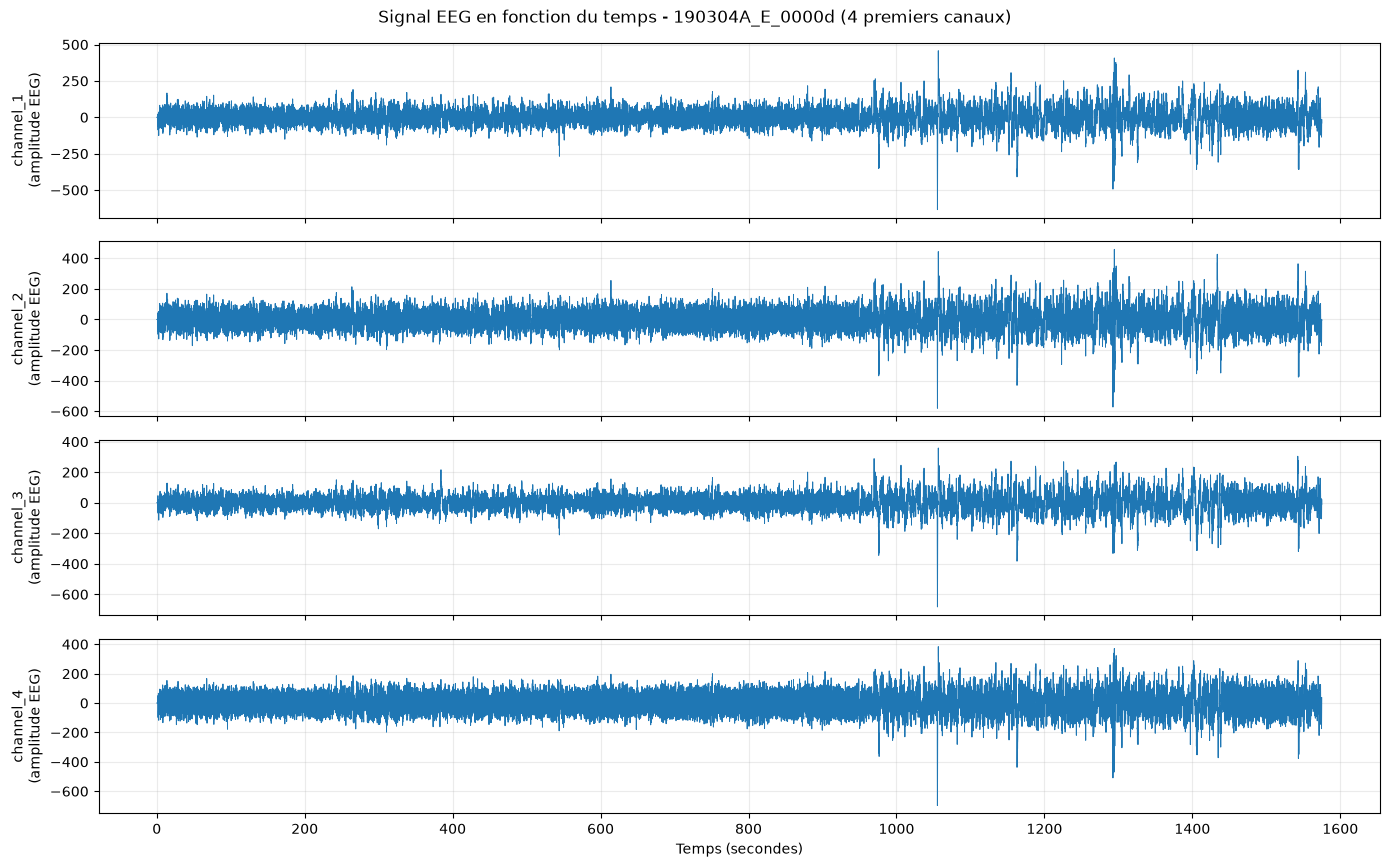

In [6]:
if len(ok_rows) and plt is None:
    print('matplotlib absent : pip install matplotlib')
elif len(ok_rows):
    step = max(1, len(eeg) // 20000)
    plot_df = eeg.iloc[::step]
    shown = signal_columns[:4]
    fig, axes = plt.subplots(len(shown), 1, figsize=(14, 2.2 * len(shown)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, shown):
        ax.plot(plot_df['time'], plot_df[col], linewidth=0.7)
        ax.set_ylabel(f'{col}\n(amplitude EEG)'); ax.grid(alpha=.25)
    axes[-1].set_xlabel('Temps (secondes)')
    fig.suptitle(f'Signal EEG en fonction du temps - {first_csv.stem} (4 premiers canaux)')
    plt.tight_layout(); plt.show()

### Réponse aux questions 1 et 2

Le tableau `exploration` donne, pour chaque enregistrement, le nombre de lignes (échantillons), de variables (`time` + canaux), la fréquence (256 Hz, recoupée par le pas de la colonne `time`), la durée totale et le nombre de valeurs manquantes. `head()` affiche les premières lignes du premier fichier. Le graphique respecte la consigne : temps en secondes en abscisse, amplitude EEG en ordonnée, titre et nom de canal. Le sujet ne précise pas l'unité de l'amplitude ; elle est donc laissée « amplitude EEG ». Les crises sont repérées avec les annotations (partie II) puis visualisées dans la partie III.

# PARTIE II - Exploitation des annotations

## Question 3 - Identifier les crises

Dans l'Excel, `DebutTrace`, `DebCE1`, `FinCE1`, `DebCE2`, ... sont des heures d'horloge. Pour chaque crise :

- début (s) = `DebCE` − `DebutTrace`
- fin (s) = `FinCE` − `DebutTrace`
- durée (s) = `FinCE` − `DebCE` (exemple `190304A-E` : 10:35:13 − 10:35:06 = 7 s)

Les lignes incohérentes (fin avant début, fin ou début manquant, durée aberrante, fin après la fin du signal) sont signalées et **exclues** du calcul des classes, sans être corrigées arbitrairement.

## Question 4 - Résumer les durées

Durée moyenne, minimale, maximale et intervalle moyen entre deux crises successives d'un même patient.

In [7]:
import datetime as dt

SECONDS_PER_DAY = 86400.0
MAX_CRISIS_SECONDS = 300.0     # une crise d'absence de plus de 5 min est consideree comme une erreur de saisie

def excel_time_to_seconds(value):
    """Heure Excel (fraction de jour, datetime.time, timedelta ou texte hh:mm:ss) -> secondes depuis minuit."""
    if value is None or (not isinstance(value, str) and pd.isna(value)):
        return np.nan
    if isinstance(value, dt.datetime):
        value = value.time()
    if isinstance(value, dt.time):
        return value.hour * 3600 + value.minute * 60 + value.second + value.microsecond / 1e6
    if isinstance(value, (dt.timedelta, pd.Timedelta)):
        return value.total_seconds() % SECONDS_PER_DAY
    if isinstance(value, str):
        try:
            parts = [float(p.replace(',', '.')) for p in value.strip().split(':')]
        except ValueError:
            return np.nan
        if len(parts) == 3:
            return parts[0] * 3600 + parts[1] * 60 + parts[2]
        if len(parts) == 2:
            return parts[0] * 3600 + parts[1] * 60
        return np.nan
    if isinstance(value, (int, float, np.number)):
        return round(float(value) * SECONDS_PER_DAY, 3)     # fraction de jour -> secondes
    return np.nan

def seconds_to_clock(seconds):
    if not np.isfinite(seconds):
        return ''
    s = int(round(seconds)) % 86400
    return f'{s // 3600:02d}:{(s % 3600) // 60:02d}:{s % 60:02d}'

annotations = pd.read_excel(ANNOTATION_PATH)
annotations.columns = [str(c).strip() for c in annotations.columns]
annotations = annotations.rename(columns={annotations.columns[0]: 'patient_id'})
annotations = annotations[annotations['patient_id'].notna()].reset_index(drop=True)   # le classeur contient ~1 million de lignes vides
annotations['patient_id'] = annotations['patient_id'].astype(str).str.strip()

# Certains patients apparaissent deux fois dans l'Excel (valeurs legerement differentes) : garder les deux
# doublerait leurs crises. On garde une seule ligne par patient ('last' = ligne la plus basse du classeur,
# supposee etre la plus recente dans un fichier _MAJ). A verifier avec l'enseignant : mettre 'first' pour l'autre ligne.
DUPLICATE_PATIENT_POLICY = 'last'
duplicated_rows = annotations[annotations['patient_id'].duplicated(keep=False)]
if len(duplicated_rows):
    print('ATTENTION - patients presents plusieurs fois dans le classeur :', sorted(duplicated_rows['patient_id'].unique()))
    display(duplicated_rows.iloc[:, :9])
    annotations = annotations.drop_duplicates('patient_id', keep=DUPLICATE_PATIENT_POLICY).reset_index(drop=True)
    print(f"-> une seule ligne conservee par patient (politique : '{DUPLICATE_PATIENT_POLICY}').")

def numbered_columns(pattern):
    found = {}
    for c in annotations.columns:
        m = re.fullmatch(pattern, c, flags=re.I)
        if m:
            found[int(m.group(1))] = c
    return found

trace_col = next(c for c in annotations.columns if re.fullmatch(r'debut\s*trace', c, flags=re.I))
nombre_col = next((c for c in annotations.columns if re.match(r'nombre', c, flags=re.I)), None)
debut_cols = numbered_columns(r'Deb\w*CE(\d+)')      # DebCE1..DebCE12 (couvre aussi DebutCE5 et DebtCE11)
fin_cols = numbered_columns(r'Fin\w*CE(\d+)')

def crisis_status(start, end):
    if not (np.isfinite(start) and np.isfinite(end)):
        return 'debut_ou_fin_manquant'
    if end <= start:
        return 'fin_avant_ou_egale_au_debut'
    if end - start > MAX_CRISIS_SECONDS:
        return 'duree_aberrante'
    return 'ok'

annotation_rows = []
for _, row in annotations.iterrows():
    trace_clock = excel_time_to_seconds(row[trace_col])
    for n in sorted(set(debut_cols) | set(fin_cols)):
        s_clock = excel_time_to_seconds(row[debut_cols[n]]) if n in debut_cols else np.nan
        e_clock = excel_time_to_seconds(row[fin_cols[n]]) if n in fin_cols else np.nan
        if not (np.isfinite(s_clock) or np.isfinite(e_clock)):
            continue
        start = round((s_clock - trace_clock) % SECONDS_PER_DAY, 3) if np.isfinite(s_clock) and np.isfinite(trace_clock) else np.nan
        end = round((e_clock - trace_clock) % SECONDS_PER_DAY, 3) if np.isfinite(e_clock) and np.isfinite(trace_clock) else np.nan
        annotation_rows.append({
            'patient_id': row['patient_id'], 'crise': n,
            'debut_trace_horloge': seconds_to_clock(trace_clock),
            'debut_horloge': seconds_to_clock(s_clock), 'fin_horloge': seconds_to_clock(e_clock),
            'start_seconds': start, 'end_seconds': end, 'duration_seconds': round(end - start, 3),
            'annotation_status': crisis_status(start, end),
            'source_start': debut_cols.get(n), 'source_end': fin_cols.get(n),
        })
annotations_long = pd.DataFrame(annotation_rows)
crises_valides = annotations_long[annotations_long['annotation_status'] == 'ok'].reset_index(drop=True)

print(f"Annotations lues : {len(annotations_long)} | valides : {len(crises_valides)} | exclues : {len(annotations_long) - len(crises_valides)}")
first = annotations_long.iloc[0]
print(f"\nVerification sur {first['patient_id']} : debut du trace {first['debut_trace_horloge']} | "
      f"crise {first['crise']} : {first['debut_horloge']} -> {first['fin_horloge']} | duree = {first['duration_seconds']:.0f} s "
      f"(debut {first['start_seconds']:.0f} s, fin {first['end_seconds']:.0f} s dans le signal)")
display(annotations_long.head())

ATTENTION - patients presents plusieurs fois dans le classeur : ['230406B-A', '230515B-G']


,patient_id,Sexe,Age,NombreCE,TypeAbs,DebutTrace,DebCE1,FinCE1,DebCE2
9,230406B-A,M,11.0,4.0,NaN,0.347500,0.349421,0.349525,0.350683
10,230515B-G,F,9.0,2.0,NaN,0.516123,0.520208,0.520370,0.520972
17,230406B-A,M,11.0,4.0,NaN,0.347500,0.349421,0.349549,0.350671
18,230515B-G,F,8.0,2.0,NaN,0.516123,0.520208,0.520359,0.521100


-> une seule ligne conservee par patient (politique : 'last').
Annotations lues : 83 | valides : 82 | exclues : 1

Verification sur 190304A-E : debut du trace 10:13:35 | crise 1 : 10:35:06 -> 10:35:13 | duree = 7 s (debut 1291 s, fin 1298 s dans le signal)


,patient_id,crise,debut_trace_horloge,debut_horloge,fin_horloge,start_seconds,end_seconds,duration_seconds,annotation_status,source_start,source_end
0,190304A-E,1,10:13:35,10:35:06,10:35:13,1291.0,1298.0,7.0,ok,DebCE1,FinCE1
1,191113A-D,1,10:18:19,10:39:13,10:39:26,1254.0,1267.0,13.0,ok,DebCE1,FinCE1
2,191113A-D,2,10:18:19,10:42:07,10:42:12,1428.0,1433.0,5.0,ok,DebCE2,FinCE2
3,210406A-F,1,15:05:17,15:15:50,15:15:58,633.0,641.0,8.0,ok,DebCE1,FinCE1
4,210427B-C,1,08:47:10,09:04:21,09:04:39,1031.0,1049.0,18.0,ok,DebCE1,FinCE1


In [8]:
# ---------- Question 3 : tableau Crise / Debut (s) / Fin (s) / Duree (s) ----------
q3_table = crises_valides[['patient_id', 'crise', 'start_seconds', 'end_seconds', 'duration_seconds']].rename(columns={
    'patient_id': 'Patient', 'crise': 'Crise', 'start_seconds': 'Début (s)', 'end_seconds': 'Fin (s)', 'duration_seconds': 'Durée (s)'})
display(q3_table)
print('Nombre total de crises (valides) :', len(q3_table))

par_patient = crises_valides.groupby('patient_id').size().rename('nombre_de_crises').reset_index()
if nombre_col:
    declare = annotations[['patient_id', nombre_col]].rename(columns={nombre_col: 'nombre_declare_excel'})
    par_patient = declare.merge(par_patient, on='patient_id', how='left').fillna({'nombre_de_crises': 0})
    par_patient['nombre_de_crises'] = par_patient['nombre_de_crises'].astype(int)
print('\nNombre de crises par patient (compare au nombre declare dans l Excel) :')
display(par_patient)

anomalies = annotations_long[annotations_long['annotation_status'] != 'ok']
print('Annotations exclues (a verifier dans le fichier Excel) :', len(anomalies))
if len(anomalies):
    display(anomalies[['patient_id', 'crise', 'debut_horloge', 'fin_horloge', 'start_seconds', 'end_seconds', 'duration_seconds', 'annotation_status']])

,Patient,Crise,Début (s),Fin (s),Durée (s)
0,190304A-E,1,1291.0,1298.0,7.0
1,191113A-D,1,1254.0,1267.0,13.0
2,191113A-D,2,1428.0,1433.0,5.0
3,210406A-F,1,633.0,641.0,8.0
4,210427B-C,1,1031.0,1049.0,18.0
...,...,...,...,...,...
77,230718A-A,3,302.0,313.0,11.0
78,230718A-A,4,430.0,441.0,11.0
79,230718A-A,5,737.0,745.0,8.0
80,230718A-A,6,974.0,986.0,12.0


Nombre total de crises (valides) : 82

Nombre de crises par patient (compare au nombre declare dans l Excel) :


,patient_id,nombre_declare_excel,nombre_de_crises
0,190304A-E,1.0,1
1,191113A-D,2.0,2
2,210406A-F,1.0,1
3,210427B-C,1.0,1
4,210504B-C,12.0,11
5,210914B-A,6.0,11
6,210928B-B,2.0,2
7,211027B-C,8.0,8
8,211104B-D,5.0,5
9,220106A-A,2.0,2


Annotations exclues (a verifier dans le fichier Excel) : 1


,patient_id,crise,debut_horloge,fin_horloge,start_seconds,end_seconds,duration_seconds,annotation_status
5,210504B-C,1,12:50:58,18:51:06,0.0,21608.0,21608.0,duree_aberrante


In [11]:
# ---------- Question 4 : statistiques des durees ----------
durations = crises_valides['duration_seconds']
gaps = []
for _, group in crises_valides.sort_values(['patient_id', 'start_seconds']).groupby('patient_id'):
    gaps.extend((group['start_seconds'].iloc[1:].to_numpy() - group['end_seconds'].iloc[:-1].to_numpy()).tolist())

crisis_stats = pd.DataFrame({
    'indicateur': ['nombre_total', 'duree_moyenne_s', 'duree_mediane_s', 'duree_minimale_s', 'duree_maximale_s', 'ecart_type_duree_s', 'intervalle_moyen_s'],
    'valeur': [len(durations), durations.mean(), durations.median(), durations.min(), durations.max(), durations.std(),
               float(np.mean(gaps)) if gaps else np.nan],
})
display(crisis_stats)
print(f"Intervalles calcules (fin d'une crise -> debut de la suivante, meme patient) : {len(gaps)}")

,indicateur,valeur
0,nombre_total,82.000000
1,duree_moyenne_s,13.243902
2,duree_mediane_s,11.000000
3,duree_minimale_s,2.000000
4,duree_maximale_s,60.000000
5,ecart_type_duree_s,10.274697
6,intervalle_moyen_s,184.603175


Intervalles calcules (fin d'une crise -> debut de la suivante, meme patient) : 63


Durees : min = 2.0 s | mediane = 11.0 s | moyenne = 13.2 s | max = 60.0 s
Coefficient de variation = 0.78
=> Non : les durees sont tres dispersees (de 2 s a 60 s, ecart-type = 10.3 s). Beaucoup de crises sont courtes et quelques-unes sont beaucoup plus longues ; la moyenne est donc tiree vers le haut par les crises longues.


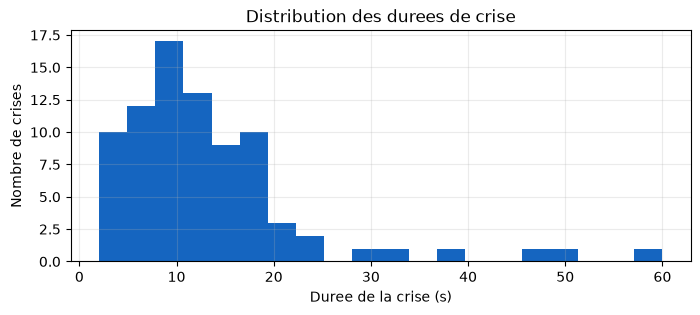

In [10]:
# ---------- Reponse a la question : les crises ont-elles une duree similaire ? ----------
cv = durations.std() / durations.mean()
print(f"Durees : min = {durations.min():.1f} s | mediane = {durations.median():.1f} s | moyenne = {durations.mean():.1f} s | max = {durations.max():.1f} s")
print(f"Coefficient de variation = {cv:.2f}")
if cv < 0.3:
    print('=> Oui : les durees sont assez homogenes.')
else:
    print(f"=> Non : les durees sont tres dispersees (de {durations.min():.0f} s a {durations.max():.0f} s, ecart-type = {durations.std():.1f} s). "
          "Beaucoup de crises sont courtes et quelques-unes sont beaucoup plus longues ; la moyenne est donc tiree vers le haut par les crises longues.")
if plt is not None:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.hist(durations, bins=20, color='#1565c0'); ax.set(xlabel='Duree de la crise (s)', ylabel='Nombre de crises', title='Distribution des durees de crise')
    ax.grid(alpha=.25); plt.show()

# PARTIE III - Construction de la variable cible

## Question 5 - Créer la colonne `class`

Pour chaque échantillon : `0` hors crise, `1` si le temps appartient à un intervalle `[début, fin]` d'une crise valide du même patient.

## Question 6 - Visualiser les classes et mesurer le déséquilibre

Le signal est affiché avec les crises surlignées ; le pourcentage d'échantillons de chaque classe est calculé.

In [12]:
def patient_key(value):
    return re.sub(r'[^A-Za-z0-9]', '', str(value)).lower()

def build_sample_labels(time_values, intervals):
    labels = np.zeros(len(time_values), dtype=np.int8)
    for start, end in intervals:
        if pd.notna(start) and pd.notna(end):
            labels[(time_values >= start) & (time_values <= end)] = 1
    return labels

def match_row_for_csv(csv_file):
    """Crises valides du patient correspondant a un fichier CSV."""
    key = patient_key(patient_from_stem(Path(csv_file).stem))
    return crises_valides[crises_valides['patient_id'].map(patient_key) == key]

signal_labeled_frames, class_by_patient = [], []
active_channels, constant_channels = {}, {}
for _, meta in ok_rows.iterrows():
    csv_file = CSV_DIR / meta['csv_file']
    header = pd.read_csv(csv_file, nrows=0).columns
    frame = pd.read_csv(csv_file, dtype={c: np.float32 for c in header if c != 'time'})
    if 'time' not in frame:
        continue
    channels = [c for c in frame.columns if c.startswith('channel_')]
    flat = [c for c in channels if float(frame[c].std()) < 1e-9]      # canaux strictement constants (pas de signal)
    constant_channels[meta['patient_id']] = flat
    active_channels[meta['patient_id']] = [c for c in channels if c not in flat]
    subset = match_row_for_csv(meta['csv_file'])
    intervals = list(zip(subset['start_seconds'], subset['end_seconds']))
    frame['class'] = build_sample_labels(frame['time'].to_numpy(), intervals)
    frame['patient_id'] = meta['patient_id']
    signal_labeled_frames.append(frame)
    class_by_patient.append({'patient_id': meta['patient_id'], 'nb_crises_valides': len(subset),
                             'nb_echantillons': len(frame), 'nb_echantillons_crise': int(frame['class'].sum()),
                             'pct_classe_1': float(frame['class'].mean() * 100), 'canaux_constants_exclus': len(flat)})

if signal_labeled_frames:
    n_total = sum(len(f) for f in signal_labeled_frames)
    n_crise = sum(int(f['class'].sum()) for f in signal_labeled_frames)
    class_counts = pd.DataFrame({'class': [0, 1], 'nombre': [n_total - n_crise, n_crise]})
    class_counts['pourcentage'] = class_counts['nombre'] / n_total * 100
    display(class_counts); display(pd.DataFrame(class_by_patient))
    flat_report = {k: v for k, v in constant_channels.items() if v}
    print('Canaux constants (exclus des caracteristiques) :', flat_report if flat_report else 'aucun')
else:
    print('Impossible de construire les classes : temps ou signaux manquants.')

,class,nombre,pourcentage
0,0,8228270,96.730708
1,1,278098,3.269292


,patient_id,nb_crises_valides,nb_echantillons,nb_echantillons_crise,pct_classe_1,canaux_constants_exclus
0,190304A_E,1,403200,1793,0.444692,0
1,191113A_D,2,463360,4610,0.994907,0
2,200625A_F,0,457728,0,0.000000,0
3,210204B_C,0,314112,0,0.000000,0
4,210208B_G,0,307200,0,0.000000,0
5,210406A_F,1,372224,2049,0.550475,0
6,210427B_C,1,318976,4609,1.444936,0
7,210504B_C,11,798976,32523,4.070585,0
8,210914B_A,11,308480,45067,14.609375,1
9,210928B_B,2,344064,14082,4.092843,1


Canaux constants (exclus des caracteristiques) : {'210914B_A': ['channel_20'], '210928B_B': ['channel_20'], '211027B_C': ['channel_20'], '211104B_D': ['channel_20'], '220121B_D': ['channel_20'], '230102B_F': ['channel_20'], '230105B_H': ['channel_20'], '230210B_D': ['channel_20'], '230224B_B': ['channel_20'], '230406B_A': ['channel_20'], '230515B_G': ['channel_20'], '230718A_A': ['channel_22']}


### Export demandé pour la partie III

Le CSV ci-dessous contient une ligne par échantillon : patient, temps, classe (`0` hors crise, `1` crise).

In [13]:
partie_III_classes = pd.concat(
    [frame[['patient_id', 'time', 'class']] for frame in signal_labeled_frames],
    ignore_index=True,
) if signal_labeled_frames else pd.DataFrame(columns=['patient_id', 'time', 'class'])
partie_III_classes['class'] = partie_III_classes['class'].astype('int8')
classes_csv = OUTPUT_DIR / 'partie_III_classes.csv'
partie_III_classes.to_csv(classes_csv, index=False)

partie_III_repartition = (
    partie_III_classes.groupby(['class'], as_index=False)
    .size()
    .rename(columns={'size': 'nombre_echantillons'})
)
partie_III_repartition['pourcentage'] = (
    partie_III_repartition['nombre_echantillons'] / len(partie_III_classes) * 100
    if len(partie_III_classes) else 0
)
display(partie_III_repartition)
print('CSV de la partie III :', classes_csv)


,class,nombre_echantillons,pourcentage
0,0,8228270,96.730708
1,1,278098,3.269292


CSV de la partie III : c:\Users\amals\Desktop\projeteeg\output\partie_III_classes.csv


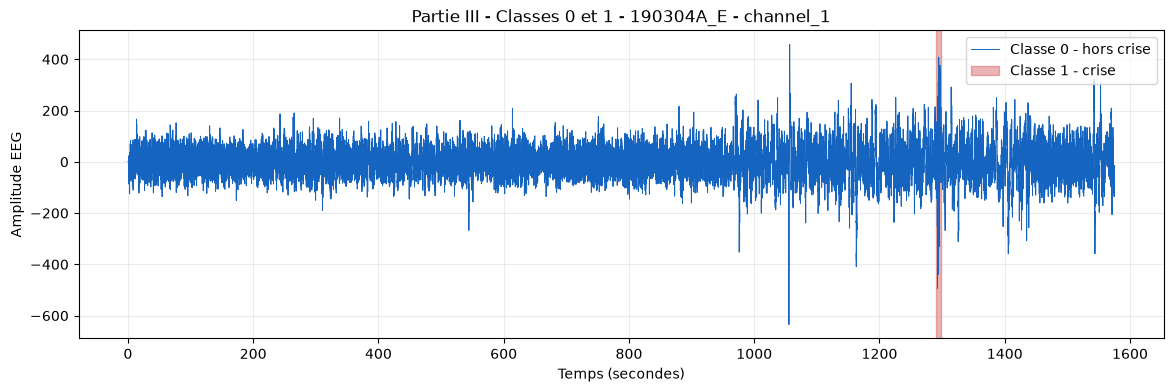

In [14]:
def crisis_runs(time_values, mask):
    """Intervalles (t_debut, t_fin) ou mask vaut 1."""
    edges = np.flatnonzero(np.diff(np.concatenate(([0], mask.astype(np.int8), [0]))))
    return [(time_values[a], time_values[b - 1]) for a, b in zip(edges[::2], edges[1::2])]

if signal_labeled_frames and plt is not None:
    labeled = next((f for f in signal_labeled_frames if f['class'].any()), signal_labeled_frames[0])
    preview = labeled.iloc[::max(1, len(labeled) // 20000)]
    channel = active_channels[labeled['patient_id'].iloc[0]][0]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(preview['time'], preview[channel], color='#1565c0', linewidth=.7, label='Classe 0 - hors crise')
    for k, (t0, t1) in enumerate(crisis_runs(labeled['time'].to_numpy(), labeled['class'].to_numpy())):
        ax.axvspan(t0, t1, color='#c62828', alpha=.35, label='Classe 1 - crise' if k == 0 else None)
    ax.set(xlabel='Temps (secondes)', ylabel='Amplitude EEG', title=f'Partie III - Classes 0 et 1 - {labeled["patient_id"].iloc[0]} - {channel}')
    ax.legend(loc='upper right'); ax.grid(alpha=.25); plt.show()

,patient_id,amplitude_rms_crise,amplitude_rms_hors_crise,rapport_crise_sur_hors_crise
0,190304A_E,323.098389,139.569031,2.314972
1,191113A_D,152.009811,102.802818,1.478654
2,210406A_F,160.064423,182.778152,0.875731
3,210427B_C,210.432419,237.967529,0.884290
4,210504B_C,125.246857,116.523468,1.074864
5,210914B_A,142.722992,105.426659,1.353766
6,210928B_B,457.317719,235.246521,1.943994
7,211027B_C,182.076233,86.181084,2.112717
8,211104B_D,263.386780,129.224319,2.038214
9,220106A_A,928.507690,903.697449,1.027454


Rapport median amplitude(crise) / amplitude(hors crise) = 1.35 ; amplitude plus forte pendant la crise chez 15/19 patients.
=> Visuellement, les crises se traduisent par une augmentation nette de l amplitude du signal (decharges plus amples).


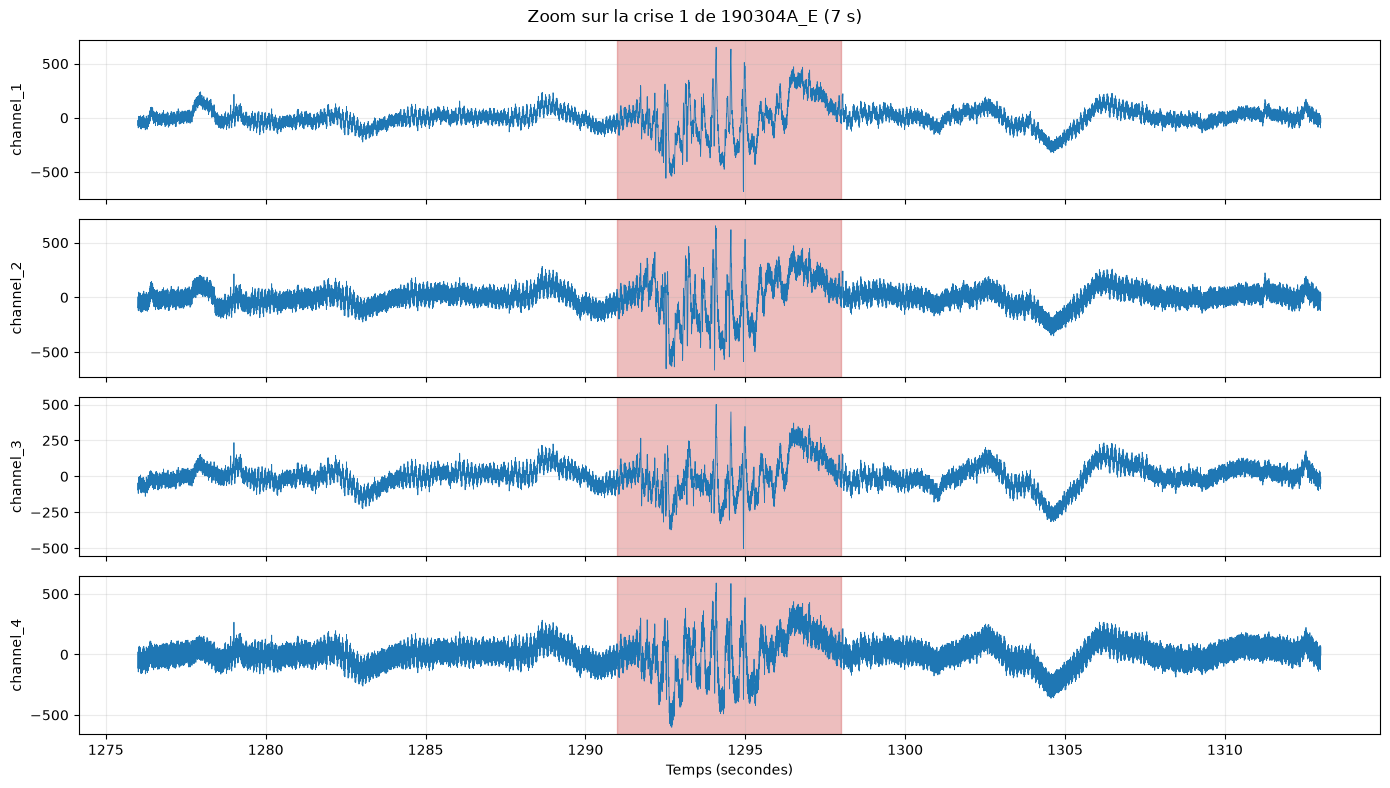

In [15]:
# ---------- Reponse : que remarque-t-on pendant les crises ? (question de la Q2) ----------
def rms_across_channels(frame, channels):
    x = frame[channels].to_numpy(dtype=np.float32)
    x = x - np.median(x, axis=0)
    return np.sqrt((x ** 2).mean(axis=1))

ratios = []
for frame in signal_labeled_frames:
    pid = frame['patient_id'].iloc[0]
    mask = frame['class'].to_numpy() == 1
    if mask.any() and (~mask).any() and active_channels[pid]:
        amp = rms_across_channels(frame, active_channels[pid])
        ratios.append({'patient_id': pid, 'amplitude_rms_crise': float(amp[mask].mean()),
                       'amplitude_rms_hors_crise': float(amp[~mask].mean()),
                       'rapport_crise_sur_hors_crise': float(amp[mask].mean() / amp[~mask].mean())})
ratios = pd.DataFrame(ratios)
if len(ratios):
    display(ratios)
    r = ratios['rapport_crise_sur_hors_crise'].median()
    plus = int((ratios['rapport_crise_sur_hors_crise'] > 1).sum())
    print(f"Rapport median amplitude(crise) / amplitude(hors crise) = {r:.2f} ; amplitude plus forte pendant la crise chez {plus}/{len(ratios)} patients.")
    if r > 1.2:
        print('=> Visuellement, les crises se traduisent par une augmentation nette de l amplitude du signal (decharges plus amples).')
    elif r < 0.8:
        print('=> Pendant les crises, l amplitude du signal diminue.')
    else:
        print('=> Pas de difference d amplitude nette en moyenne : la crise se reconnait surtout par un changement de forme / de rythme.')

# zoom autour de la premiere crise du premier patient annote
if plt is not None and len(crises_valides):
    pid_zoom = next(f['patient_id'].iloc[0] for f in signal_labeled_frames if f['class'].any())
    frame = next(f for f in signal_labeled_frames if f['patient_id'].iloc[0] == pid_zoom)
    c0 = crises_valides[crises_valides['patient_id'].map(patient_key) == patient_key(pid_zoom)].iloc[0]
    lo, hi = c0['start_seconds'] - 15, c0['end_seconds'] + 15
    zoom = frame[(frame['time'] >= lo) & (frame['time'] <= hi)]
    shown = active_channels[pid_zoom][:4]
    fig, axes = plt.subplots(len(shown), 1, figsize=(14, 2 * len(shown)), sharex=True)
    for ax, col in zip(np.atleast_1d(axes), shown):
        ax.plot(zoom['time'], zoom[col], linewidth=.6); ax.axvspan(c0['start_seconds'], c0['end_seconds'], color='#c62828', alpha=.3)
        ax.set_ylabel(col); ax.grid(alpha=.25)
    np.atleast_1d(axes)[-1].set_xlabel('Temps (secondes)')
    fig.suptitle(f'Zoom sur la crise {c0["crise"]} de {pid_zoom} ({c0["duration_seconds"]:.0f} s)'); plt.tight_layout(); plt.show()

In [16]:
# ---------- Reponse a la question de la Q6 : le desequilibre est-il important ? ----------
p0 = float(class_counts.loc[class_counts['class'] == 0, 'pourcentage'].iloc[0])
p1 = float(class_counts.loc[class_counts['class'] == 1, 'pourcentage'].iloc[0])
print(f"Classe 0 (hors crise) : {p0:.2f} % des echantillons")
print(f"Classe 1 (crise)      : {p1:.2f} % des echantillons")
if p1 > 0:
    print(f"Rapport : environ {p0 / p1:.0f} echantillons hors crise pour 1 echantillon de crise.")
if p1 < 20:
    print("=> Oui, le desequilibre est tres important. Un modele qui predirait toujours « pas de crise » aurait une accuracy "
          f"de {p0:.1f} % sans detecter aucune crise : l'accuracy seule est trompeuse (recall, precision et F1 sur la classe 1 seront necessaires), "
          "et il faudra traiter ce desequilibre (stratification, class_weight, reechantillonnage).")
else:
    print('=> Desequilibre modere.')

Classe 0 (hors crise) : 96.73 % des echantillons
Classe 1 (crise)      : 3.27 % des echantillons
Rapport : environ 30 echantillons hors crise pour 1 echantillon de crise.
=> Oui, le desequilibre est tres important. Un modele qui predirait toujours « pas de crise » aurait une accuracy de 96.7 % sans detecter aucune crise : l'accuracy seule est trompeuse (recall, precision et F1 sur la classe 1 seront necessaires), et il faudra traiter ce desequilibre (stratification, class_weight, reechantillonnage).


# PARTIE IV - Segmentation du signal

## Question 7 - Découper le signal en fenêtres

Fenêtres de 2 secondes avec un recouvrement de 50 %. À 256 Hz : 512 échantillons par fenêtre, pas de 256 échantillons. Une fenêtre est de classe 1 si **au moins 50 %** de ses échantillons sont en crise. La segmentation est faite patient par patient (une fenêtre ne chevauche jamais deux enregistrements).

In [17]:
WINDOW_SECONDS = 2.0
OVERLAP = 0.50
DEFAULT_FS_FROM_PDF = 256.0

def segment_signal(frame, fs, channels=None, window_seconds=WINDOW_SECONDS, overlap=OVERLAP):
    n_window = int(round(fs * window_seconds))
    step = max(1, int(round(n_window * (1 - overlap))))
    if n_window <= 0 or len(frame) < n_window:
        return []
    channels = channels or [c for c in frame.columns if c.startswith('channel_')]
    values = frame[channels].to_numpy(dtype=np.float32)
    labels = frame['class'].to_numpy()
    times = frame['time'].to_numpy()
    cumulative = np.concatenate(([0], np.cumsum(labels, dtype=np.int64)))      # nb d'echantillons de crise cumule
    segments = []
    for start in range(0, len(frame) - n_window + 1, step):
        stop = start + n_window
        crisis_fraction = (cumulative[stop] - cumulative[start]) / n_window
        segments.append({'window_start': start, 'window_end': stop, 'start_seconds': float(times[start]),
                         'end_seconds': float(times[stop - 1]), 'crisis_fraction': float(crisis_fraction),
                         'class': int(crisis_fraction >= 0.5), 'signals': values[start:stop]})
    return segments

all_windows = []
for frame in signal_labeled_frames:
    pid = frame['patient_id'].iloc[0]
    fs = ok_rows.loc[ok_rows['patient_id'] == pid, 'frequence_d_echantillonnage'].iloc[0]
    if pd.notna(fs):
        for window_id, item in enumerate(segment_signal(frame, fs, active_channels[pid]), start=1):
            item.update({'patient_id': pid, 'window': window_id})
            all_windows.append(item)

windows_summary = pd.DataFrame([{k: v for k, v in item.items() if k != 'signals'} for item in all_windows])
display(windows_summary.head())
if len(windows_summary):
    print('Taille d une fenetre :', all_windows[0]['signals'].shape[0], 'echantillons')
    display(windows_summary['class'].value_counts().rename_axis('class').reset_index(name='nombre_de_fenetres'))
    display(windows_summary.groupby('patient_id').agg(fenetres=('window', 'size'), fenetres_crise=('class', 'sum')).reset_index())

,window_start,window_end,start_seconds,end_seconds,crisis_fraction,class,patient_id,window
0,0,512,0.0,1.996094,0.0,0,190304A_E,1
1,256,768,1.0,2.996094,0.0,0,190304A_E,2
2,512,1024,2.0,3.996094,0.0,0,190304A_E,3
3,768,1280,3.0,4.996094,0.0,0,190304A_E,4
4,1024,1536,4.0,5.996094,0.0,0,190304A_E,5


Taille d une fenetre : 512 echantillons


,class,nombre_de_fenetres
0,0,32038
1,1,1168


,patient_id,fenetres,fenetres_crise
0,190304A_E,1574,8
1,191113A_D,1809,20
2,200625A_F,1787,0
3,210204B_C,1226,0
4,210208B_G,1199,0
5,210406A_F,1453,9
6,210427B_C,1245,19
7,210504B_C,3120,138
8,210914B_A,1204,187
9,210928B_B,1343,57


### Réponse à la question 7

`windows_summary` contient une ligne par fenêtre EEG (position, temps de début et de fin, fraction de crise, classe). Pour 256 Hz : 512 échantillons par fenêtre et décalage de 256 échantillons ; un enregistrement de `N` échantillons donne `(N − 512) // 256 + 1` fenêtres. Les nombres de fenêtres des classes 0 et 1 sont affichés ci-dessus. Le déséquilibre des classes persiste au niveau des fenêtres : les fenêtres de crise sont minoritaires.

# PARTIE V - Extraction des caractéristiques temporelles

## Question 8 - Construire le dataset

Pour chaque fenêtre, on calcule : moyenne, écart-type, variance, minimum, maximum, amplitude (max − min), RMS et énergie (somme des carrés).

- `features_per_channel` : les 8 caractéristiques **pour chaque canal** (colonnes `channel_k_mean`, ...).
- `features` : le dataset **au format du PDF** — une ligne = une fenêtre, colonnes `Window Mean Std Variance Min Max Amplitude RMS Energy Class`. Les caractéristiques de chaque canal actif sont moyennées sur les canaux, ce qui rend le dataset comparable entre patients dont le nombre de canaux diffère (12, 21 ou 23).

In [18]:
FEATURE_NAMES = ['mean', 'std', 'variance', 'min', 'max', 'amplitude', 'rms', 'energy']

def window_channel_features(x):
    """x : (n_echantillons, n_canaux) -> dict de vecteurs (un element par canal)."""
    x = np.asarray(x, dtype=np.float64)
    maximum, minimum = x.max(axis=0), x.min(axis=0)
    return {'mean': x.mean(axis=0), 'std': x.std(axis=0), 'variance': x.var(axis=0), 'min': minimum, 'max': maximum,
            'amplitude': maximum - minimum, 'rms': np.sqrt((x ** 2).mean(axis=0)), 'energy': (x ** 2).sum(axis=0)}

def extract_temporal_features(windows):
    rows_channel, rows_pdf = [], []
    for global_id, item in enumerate(windows, start=1):
        feats = window_channel_features(item['signals'])
        meta = {'patient_id': item['patient_id'], 'window_in_patient': item['window'],
                'window_start': item['start_seconds'], 'window_end': item['end_seconds']}
        rows_pdf.append({'Window': global_id, **meta,
                         **{name.capitalize() if name not in ('rms',) else 'RMS': float(feats[name].mean()) for name in FEATURE_NAMES},
                         'Class': item['class']})
        row = {**meta, 'Class': item['class']}
        for ch_idx in range(item['signals'].shape[1]):
            for name in FEATURE_NAMES:
                row[f'channel_{ch_idx + 1}_{name}'] = float(feats[name][ch_idx])
        rows_channel.append(row)
    return pd.DataFrame(rows_pdf), pd.DataFrame(rows_channel)

features, features_per_channel = extract_temporal_features(all_windows)
features = features[['Window', 'patient_id', 'window_in_patient', 'window_start', 'window_end',
                     'Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Class']]
features.to_csv(OUTPUT_DIR / 'window_features.csv', index=False)
features_per_channel.to_csv(OUTPUT_DIR / 'window_features_per_channel.csv', index=False)
display(features.head()); print('Nombre de fenetres :', len(features))

,Window,patient_id,window_in_patient,window_start,window_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Class
0,1,190304A_E,1,0.0,1.996094,-3.840028,45.414005,7420.294970,-162.682044,122.971378,285.653422,48.188571,4.038866e+06,0
1,2,190304A_E,2,1.0,2.996094,-10.044156,66.807073,17373.907601,-167.537631,135.832106,303.369737,76.477522,1.046627e+07,0
2,3,190304A_E,3,2.0,3.996094,-5.382459,70.782379,20345.164237,-162.022058,141.570059,303.592117,82.366393,1.262362e+07,0
3,4,190304A_E,4,3.0,4.996094,1.096169,72.754141,20368.771015,-158.182249,154.988651,313.170900,80.624167,1.190329e+07,0
4,5,190304A_E,5,4.0,5.996094,2.143481,73.946677,20329.547732,-159.017287,177.708507,336.725794,79.385766,1.116985e+07,0


Nombre de fenetres : 33206


In [19]:
window_counts = features['Class'].value_counts().sort_index().rename_axis('Class').reset_index(name='nombre')
window_counts['pourcentage'] = window_counts['nombre'] / len(features) * 100
display(window_counts)
print('Nombre total de fenetres        :', len(features))
print('Nombre de fenetres de classe 0  :', int((features['Class'] == 0).sum()))
print('Nombre de fenetres de classe 1  :', int((features['Class'] == 1).sum()))
print('Colonnes du dataset final       :', list(features.columns))

,Class,nombre,pourcentage
0,0,32038,96.482563
1,1,1168,3.517437


Nombre total de fenetres        : 33206
Nombre de fenetres de classe 0  : 32038
Nombre de fenetres de classe 1  : 1168
Colonnes du dataset final       : ['Window', 'patient_id', 'window_in_patient', 'window_start', 'window_end', 'Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Class']


### Réponse à la question 8

`features` est le dataset de la partie V : une ligne = une fenêtre EEG, avec `Mean, Std, Variance, Min, Max, Amplitude, RMS, Energy` et `Class` (`patient_id`, `window_in_patient`, `window_start`, `window_end` servent à retrouver la fenêtre dans le signal, par exemple pour reconstruire les crises plus tard). Les vérifications demandées (nombre total de fenêtres, nombre de fenêtres de classe 0 et de classe 1) sont affichées ci-dessus. La version détaillée par canal est dans `features_per_channel`.

## Association annotations-signaux et contrôles de cohérence

Cette table relie chaque annotation au signal du patient et indique les erreurs éventuelles (annotation exclue, signal manquant, fin après la fin du signal).

In [20]:
def validation_message(row):
    errors = []
    if row['annotation_status'] != 'ok':
        errors.append(row['annotation_status'])
    if pd.isna(row.get('duree_signal')):
        errors.append('signal_introuvable')
    elif pd.notna(row.get('end_seconds')) and row['end_seconds'] > row['duree_signal']:
        errors.append('fin_apres_signal')
    return '; '.join(errors) if errors else 'ok'

joined = annotations_long.copy()
joined['patient_key'] = joined['patient_id'].map(patient_key)
summary = dataset_summary.rename(columns={'patient_id': 'patient_id_signal'}).copy()
summary['patient_key'] = summary['patient_id_signal'].map(patient_key)
joined = joined.merge(summary, on='patient_key', how='left')
joined['validation_message'] = joined.apply(validation_message, axis=1)
joined['annotation_valid'] = joined['validation_message'].eq('ok')
joined.to_csv(OUTPUT_DIR / 'annotations_with_signals.csv', index=False)
display(joined[['patient_id', 'crise', 'start_seconds', 'end_seconds', 'duration_seconds', 'duree_signal', 'validation_message']].head(10))
display(joined['annotation_valid'].value_counts(dropna=False).rename_axis('annotation_valid').reset_index(name='nombre'))
display(joined.loc[~joined['annotation_valid'], ['patient_id', 'crise', 'debut_horloge', 'fin_horloge', 'validation_message']])

,patient_id,crise,start_seconds,end_seconds,duration_seconds,duree_signal,validation_message
0,190304A-E,1,1291.0,1298.0,7.0,1575.0,ok
1,191113A-D,1,1254.0,1267.0,13.0,1810.0,ok
2,191113A-D,2,1428.0,1433.0,5.0,1810.0,ok
3,210406A-F,1,633.0,641.0,8.0,1454.0,ok
4,210427B-C,1,1031.0,1049.0,18.0,1246.0,ok
5,210504B-C,1,0.0,21608.0,21608.0,3121.0,duree_aberrante; fin_apres_signal
6,210504B-C,2,731.0,747.0,16.0,3121.0,ok
7,210504B-C,3,1041.0,1047.0,6.0,3121.0,ok
8,210504B-C,4,1126.0,1129.0,3.0,3121.0,ok
9,210504B-C,5,1217.0,1220.0,3.0,3121.0,ok


,annotation_valid,nombre
0,True,82
1,False,1


,patient_id,crise,debut_horloge,fin_horloge,validation_message
5,210504B-C,1,12:50:58,18:51:06,duree_aberrante; fin_apres_signal


## Visualisation interactive auxiliaire

Interface Plotly facultative (hors sujet) : signal du premier enregistrement avec les crises valides surlignées.

In [21]:
def create_html_interface(csv_dir=None, output_path=None):
    csv_dir = CSV_DIR if csv_dir is None else csv_dir
    output_path = VIZ_DIR / 'eeg_visualization.html' if output_path is None else output_path
    try:
        import plotly.graph_objects as go
        from plotly.offline import plot
    except ImportError:
        print('Plotly absent : interface non generee (pip install plotly).')
        return None
    if not len(ok_rows):
        print('Aucun signal converti : interface non generee.')
        return None
    meta = ok_rows.iloc[0]
    frame = pd.read_csv(csv_dir / meta['csv_file'])
    if 'time' not in frame:
        print('Colonne time absente : interface non generee.')
        return None
    fig = go.Figure()
    colors = ['#1565c0', '#ef6c00', '#2e7d32', '#8e24aa', '#00838f', '#c62828', '#6d4c41', '#283593']
    for i, col in enumerate([c for c in frame.columns if c.startswith('channel_')][:8]):
        fig.add_trace(go.Scattergl(x=frame['time'], y=frame[col], name=col, line={'color': colors[i % len(colors)]}))
    for _, ann in match_row_for_csv(meta['csv_file']).iterrows():
        fig.add_vrect(x0=ann['start_seconds'], x1=ann['end_seconds'], fillcolor='#d32f2f', opacity=.18, line_width=1, annotation_text=f"Crise {ann['crise']}")
    fig.update_layout(title=f"EEG - {meta['patient_id']}", xaxis_title='Temps (secondes)', yaxis_title='Amplitude', template='plotly_white', hovermode='x unified')
    plot(fig, filename=str(output_path), auto_open=False, include_plotlyjs=True)
    return output_path

html_path = create_html_interface()
print('Interface :', html_path)

Interface : c:\Users\amals\Desktop\projeteeg\visualization\eeg_visualization.html


## Bilan des 5 premières parties

- Partie I : exploration de tous les enregistrements (lignes, variables, fréquence, durée, valeurs manquantes) et visualisation temporelle.
- Partie II : crises extraites de l'Excel avec la bonne convention (heure de crise − heure de début du trace), statistiques de durée.
- Partie III : classe 0/1 par échantillon, graphique, pourcentage de chaque classe.
- Partie IV : fenêtres de 2 s, recouvrement 50 %, classe 1 si au moins 50 % de crise.
- Partie V : caractéristiques temporelles par fenêtre (dataset au format du PDF + version par canal).

In [22]:
bilan = {
    'fichiers_mat_donnees': int(len(files['data_mat_files'])),
    'fichiers_convertis': int((dataset_summary['status_conversion'] == 'ok').sum()),
    'patients': int(dataset_summary['patient_id'].nunique()),
    'annotations_lues': int(len(annotations_long)),
    'crises_valides': int(len(crises_valides)),
    'crises_exclues': int(len(annotations_long) - len(crises_valides)),
    'fenetres': int(len(features)),
    'fenetres_classe_0': int((features['Class'] == 0).sum()),
    'fenetres_classe_1': int((features['Class'] == 1).sum()),
}
display(pd.Series(bilan, name='valeur').to_frame())
print('Fichiers generes :', OUTPUT_DIR / 'dataset_summary.csv', OUTPUT_DIR / 'annotations_with_signals.csv',
      OUTPUT_DIR / 'window_features.csv', OUTPUT_DIR / 'window_features_per_channel.csv', OUTPUT_DIR / 'partie_III_classes.csv')

,valeur
fichiers_mat_donnees,22
fichiers_convertis,22
patients,22
annotations_lues,83
crises_valides,82
crises_exclues,1
fenetres,33206
fenetres_classe_0,32038
fenetres_classe_1,1168


Fichiers generes : c:\Users\amals\Desktop\projeteeg\output\dataset_summary.csv c:\Users\amals\Desktop\projeteeg\output\annotations_with_signals.csv c:\Users\amals\Desktop\projeteeg\output\window_features.csv c:\Users\amals\Desktop\projeteeg\output\window_features_per_channel.csv c:\Users\amals\Desktop\projeteeg\output\partie_III_classes.csv


# PARTIE VI - Analyse fréquentielle

## Question 9 - Puissance du signal dans les bandes de fréquence

L'EEG contient aussi de l'information dans le **domaine fréquentiel**. Pour chaque fenêtre, on calcule la transformée de Fourier rapide (FFT), puis la puissance dans quatre bandes :

| Bande | Fréquence |
|---|---|
| Delta | 0,5 – 4 Hz |
| Theta | 4 – 8 Hz |
| Alpha | 8 – 13 Hz |
| Beta | 13 – 30 Hz |

Méthode : on retire la moyenne de la fenêtre (composante continue), on calcule la FFT de chaque canal, la puissance `|X(f)|² / N` pour chaque fréquence, puis on additionne les puissances des fréquences de la bande. Comme en partie V, on **moyenne sur les canaux** pour obtenir une seule valeur par fenêtre.

In [23]:
BANDS = {'Delta': (0.5, 4.0), 'Theta': (4.0, 8.0), 'Alpha': (8.0, 13.0), 'Beta': (13.0, 30.0)}
fs_by_patient = ok_rows.set_index('patient_id')['frequence_d_echantillonnage'].to_dict()

def window_band_powers(x, fs):
    """x : (n_echantillons, n_canaux) -> puissance par bande, moyennee sur les canaux."""
    x = np.asarray(x, dtype=np.float64)
    x = x - x.mean(axis=0)                                   # retire la composante continue
    spectrum = np.fft.rfft(x, axis=0)
    freqs = np.fft.rfftfreq(x.shape[0], d=1.0 / fs)
    power = (np.abs(spectrum) ** 2) / x.shape[0]             # puissance par frequence et par canal
    out = {}
    for name, (lo, hi) in BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        out[name] = float(power[mask].sum(axis=0).mean())    # somme sur la bande, moyenne sur les canaux
    return out

band_rows = [window_band_powers(item['signals'], fs_by_patient[item['patient_id']]) for item in all_windows]
band_df = pd.DataFrame(band_rows, index=features.index)      # meme ordre que all_windows / features

features_freq = features.copy()
for name in BANDS:
    features_freq[name] = band_df[name].to_numpy()
# la colonne Class est placee en dernier, comme dans le PDF
features_freq = features_freq[[c for c in features_freq.columns if c != 'Class'] + ['Class']]
features_freq.to_csv(OUTPUT_DIR / 'window_features_freq.csv', index=False)

display(features_freq.head())
print('Colonnes :', list(features_freq.columns))
print('Nombre de fenetres :', len(features_freq))

,Window,patient_id,window_in_patient,window_start,window_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Delta,Theta,Alpha,Beta,Class
0,1,190304A_E,1,0.0,1.996094,-3.840028,45.414005,7420.294970,-162.682044,122.971378,285.653422,48.188571,4.038866e+06,263299.727254,19649.712487,32747.663468,34462.081003,0
1,2,190304A_E,2,1.0,2.996094,-10.044156,66.807073,17373.907601,-167.537631,135.832106,303.369737,76.477522,1.046627e+07,202605.876858,54344.535135,77211.683450,76332.983890,0
2,3,190304A_E,3,2.0,3.996094,-5.382459,70.782379,20345.164237,-162.022058,141.570059,303.592117,82.366393,1.262362e+07,53159.444407,58367.106661,85691.744120,72785.200325,0
3,4,190304A_E,4,3.0,4.996094,1.096169,72.754141,20368.771015,-158.182249,154.988651,313.170900,80.624167,1.190329e+07,83352.311542,57986.669845,119150.011719,70694.053362,0
4,5,190304A_E,5,4.0,5.996094,2.143481,73.946677,20329.547732,-159.017287,177.708507,336.725794,79.385766,1.116985e+07,66818.682829,70070.662145,138537.751973,89463.512182,0


Colonnes : ['Window', 'patient_id', 'window_in_patient', 'window_start', 'window_end', 'Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Delta', 'Theta', 'Alpha', 'Beta', 'Class']
Nombre de fenetres : 33206


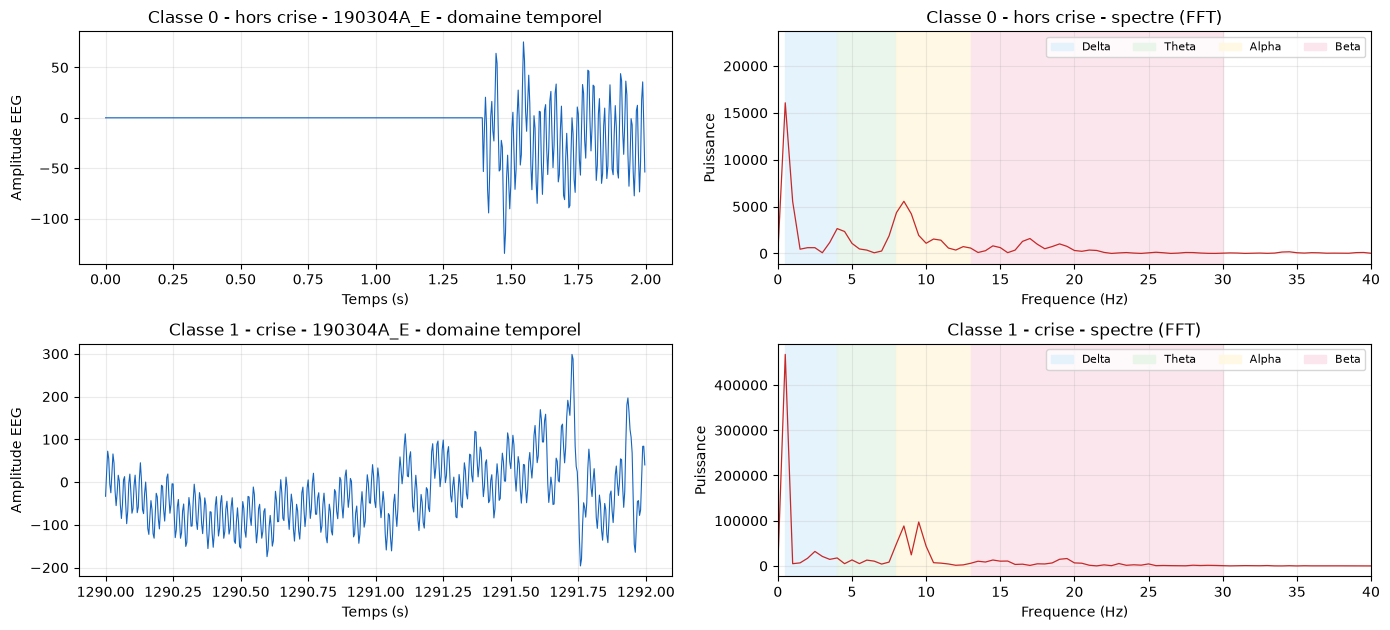

In [24]:
# Representation d'une fenetre : signal dans le domaine temporel + spectre frequentiel (classe 0 vs classe 1)
def pick_window(class_value, patient=None):
    for item in all_windows:
        if item['class'] == class_value and (patient is None or item['patient_id'] == patient):
            return item
    return None

patient_with_crisis = next((item['patient_id'] for item in all_windows if item['class'] == 1), None)
examples = [('Classe 0 - hors crise', pick_window(0, patient_with_crisis)),
            ('Classe 1 - crise', pick_window(1, patient_with_crisis))]
examples = [(label, w) for label, w in examples if w is not None]

if plt is not None and examples:
    fig, axes = plt.subplots(len(examples), 2, figsize=(14, 3.2 * len(examples)), squeeze=False)
    for row, (label, w) in zip(axes, examples):
        fs = fs_by_patient[w['patient_id']]
        sig = w['signals'][:, 0].astype(np.float64)                # premier canal actif
        t = w['start_seconds'] + np.arange(len(sig)) / fs
        row[0].plot(t, sig, linewidth=.8, color='#1565c0')
        row[0].set(xlabel='Temps (s)', ylabel='Amplitude EEG', title=f"{label} - {w['patient_id']} - domaine temporel")
        spec = np.abs(np.fft.rfft(sig - sig.mean())) ** 2 / len(sig)
        freqs = np.fft.rfftfreq(len(sig), d=1.0 / fs)
        row[1].plot(freqs, spec, linewidth=.9, color='#c62828')
        for (name, (lo, hi)), shade in zip(BANDS.items(), ['#e3f2fd', '#e8f5e9', '#fff8e1', '#fce4ec']):
            row[1].axvspan(lo, hi, color=shade, alpha=.9, label=name)
        row[1].set(xlim=(0, 40), xlabel='Frequence (Hz)', ylabel='Puissance', title=f'{label} - spectre (FFT)')
        row[1].legend(fontsize=8, ncol=4); row[0].grid(alpha=.25); row[1].grid(alpha=.25)
    plt.tight_layout(); plt.show()
else:
    print('Pas de fenetre de classe 1 ou matplotlib absent : graphique non genere.')

### Réponse à la question 9

`features_freq` contient maintenant 4 variables supplémentaires (`Delta`, `Theta`, `Alpha`, `Beta`) en plus des 8 caractéristiques temporelles : le dataset passe à **12 variables + `Class`**. Le graphique compare une fenêtre hors crise et une fenêtre de crise du même patient. Le signal (à gauche) est vu dans le temps ; le spectre (à droite) montre quelles fréquences contiennent de la puissance. Les crises d'absence sont des décharges rythmiques lentes : on s'attend donc à ce que la puissance augmente surtout dans les basses fréquences (Delta / Theta). Les moyennes par classe de la partie VII permettent de le vérifier sur toutes les fenêtres.

# PARTIE VII - Analyse exploratoire

Avant d'entraîner les modèles, on analyse les caractéristiques obtenues.

## Question 10 - Comparer les caractéristiques entre les deux classes

In [26]:
FEATURE_COLS = ['Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS', 'Energy', 'Delta', 'Theta', 'Alpha', 'Beta']
data = features_freq[FEATURE_COLS + ['Class']].copy()

# Moyenne et mediane par classe (la mediane est utile car Energy et les puissances ont des valeurs extremes)
comparison = data.groupby('Class')[FEATURE_COLS].agg(['mean', 'median']).T.unstack(level=-1)
comparison.columns = [f'classe_{c}_{stat}' for stat, c in comparison.columns]
comparison = comparison[[c for c in comparison.columns if c.endswith('_mean')] + [c for c in comparison.columns if c.endswith('_median')]]
if {'classe_0_mean', 'classe_1_mean'} <= set(comparison.columns):
    comparison['rapport_moyenne_1_sur_0'] = comparison['classe_1_mean'] / comparison['classe_0_mean']
display(comparison)

# Exemples demandes par le PDF
for col in ['Energy', 'Delta', 'Theta', 'Std']:
    m0 = data.loc[data['Class'] == 0, col].mean(); m1 = data.loc[data['Class'] == 1, col].mean()
    print(f'{col:<7}: moyenne classe 0 = {m0:.4g} | moyenne classe 1 = {m1:.4g} | rapport 1/0 = {m1 / m0:.2f}')

""
Mean
Std
Variance
Min
Max
Amplitude
RMS
Energy
Delta
Theta


Energy : moyenne classe 0 = 4.435e+08 | moyenne classe 1 = 2.388e+08 | rapport 1/0 = 0.54
Delta  : moyenne classe 0 = 6.698e+07 | moyenne classe 1 = 1.542e+07 | rapport 1/0 = 0.23
Theta  : moyenne classe 0 = 4.856e+06 | moyenne classe 1 = 1.335e+06 | rapport 1/0 = 0.27
Std    : moyenne classe 0 = 122.3 | moyenne classe 1 = 173 | rapport 1/0 = 1.41


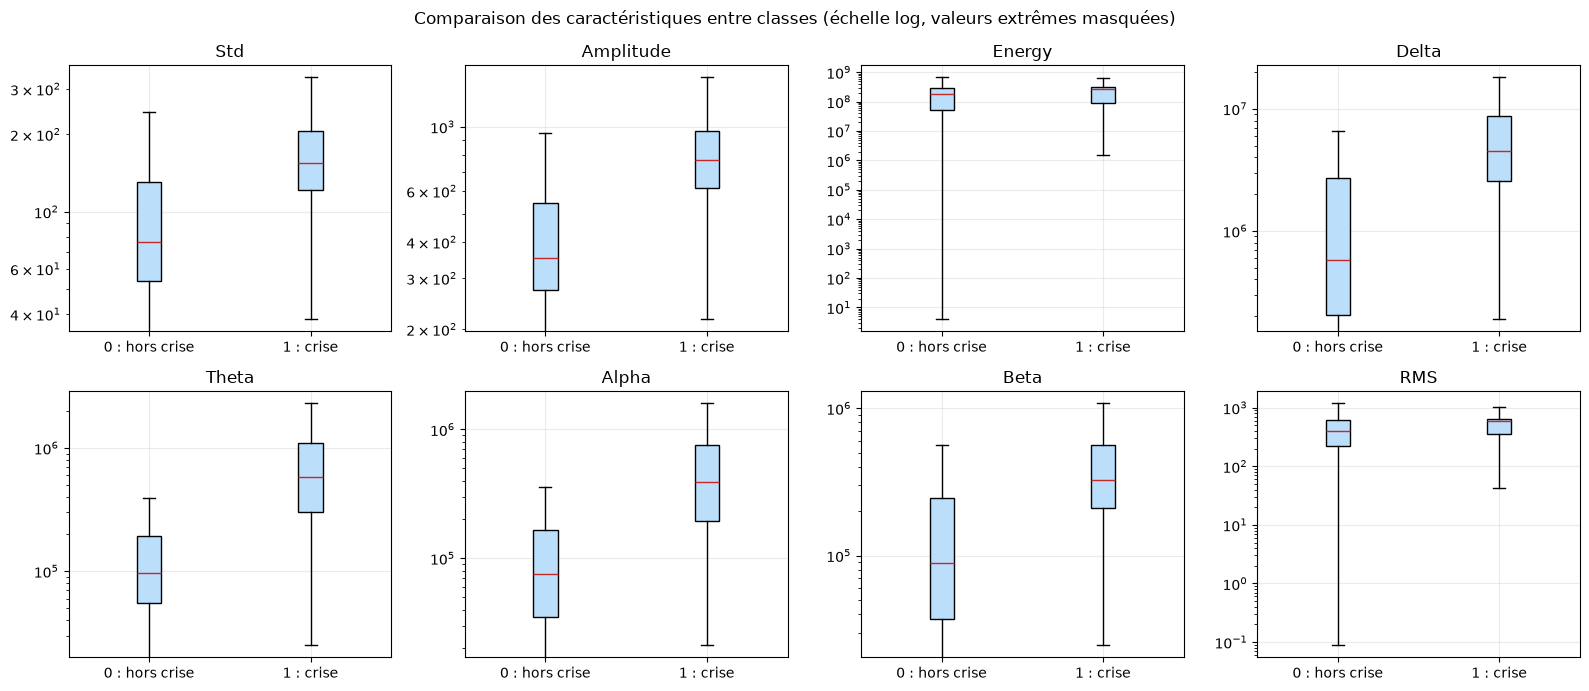

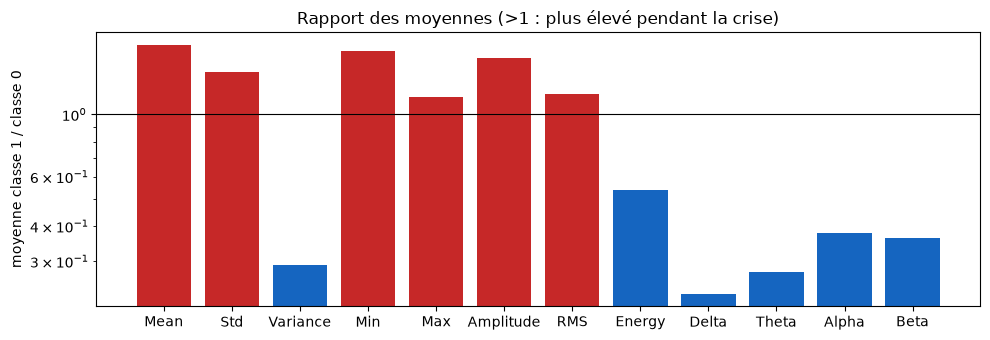

In [27]:
if plt is not None and data['Class'].nunique() == 2:
    show = ['Std', 'Amplitude', 'Energy', 'Delta', 'Theta', 'Alpha', 'Beta', 'RMS']
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, col in zip(axes.ravel(), show):
        groups = [data.loc[data['Class'] == c, col].to_numpy() for c in (0, 1)]
        ax.boxplot(groups, tick_labels=['0 : hors crise', '1 : crise'], showfliers=False, patch_artist=True,
                   boxprops={'facecolor': '#bbdefb'}, medianprops={'color': '#c62828'})
        ax.set_yscale('log'); ax.set_title(col); ax.grid(alpha=.25)
    fig.suptitle('Comparaison des caractéristiques entre classes (échelle log, valeurs extrêmes masquées)')
    plt.tight_layout(); plt.show()

    # Diagramme en barres : rapport des moyennes classe 1 / classe 0
    ratio = (data.groupby('Class')[FEATURE_COLS].mean().loc[1] / data.groupby('Class')[FEATURE_COLS].mean().loc[0])
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(ratio.index, ratio.values, color=['#c62828' if v > 1 else '#1565c0' for v in ratio.values])
    ax.axhline(1, color='k', linewidth=.8); ax.set_yscale('log')
    ax.set(ylabel='moyenne classe 1 / classe 0', title='Rapport des moyennes (>1 : plus élevé pendant la crise)')
    ax.grid(alpha=.25, axis='y'); plt.tight_layout(); plt.show()
else:
    print('Graphique non genere (matplotlib absent ou une seule classe presente).')

### Réponse à la question 10

Le tableau donne la moyenne (et la médiane) de chaque caractéristique pour la classe 0 et la classe 1, ainsi que leur rapport. Un rapport nettement supérieur à 1 signifie que la caractéristique est plus grande pendant la crise. Les boîtes à moustaches et les barres montrent les mêmes différences graphiquement (échelle logarithmique, car l'énergie et les puissances ont des valeurs très étalées). À commenter dans le rapport avec les valeurs obtenues : quelles caractéristiques changent le plus entre les deux classes, et dans quel sens.

## Question 11 - Matrice de corrélation

,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Delta,Theta,Alpha,Beta
Mean,1.00,0.18,0.08,0.68,0.71,0.13,-0.17,0.06,0.08,0.05,0.03,0.03
Std,0.18,1.00,0.77,-0.53,0.76,0.95,0.64,0.70,0.72,0.59,0.57,0.52
Variance,0.08,0.77,1.00,-0.42,0.54,0.70,0.47,0.85,0.98,0.70,0.71,0.62
Min,0.68,-0.53,-0.42,1.00,0.06,-0.59,-0.58,-0.41,-0.38,-0.37,-0.39,-0.35
Max,0.71,0.76,0.54,0.06,1.00,0.77,0.31,0.47,0.49,0.48,0.46,0.44
Amplitude,0.13,0.95,0.70,-0.59,0.77,1.00,0.63,0.64,0.64,0.63,0.62,0.58
RMS,-0.17,0.64,0.47,-0.58,0.31,0.63,1.00,0.55,0.46,0.36,0.35,0.31
Energy,0.06,0.70,0.85,-0.41,0.47,0.64,0.55,1.00,0.84,0.59,0.58,0.51
Delta,0.08,0.72,0.98,-0.38,0.49,0.64,0.46,0.84,1.00,0.63,0.62,0.52
Theta,0.05,0.59,0.70,-0.37,0.48,0.63,0.36,0.59,0.63,1.00,0.89,0.84


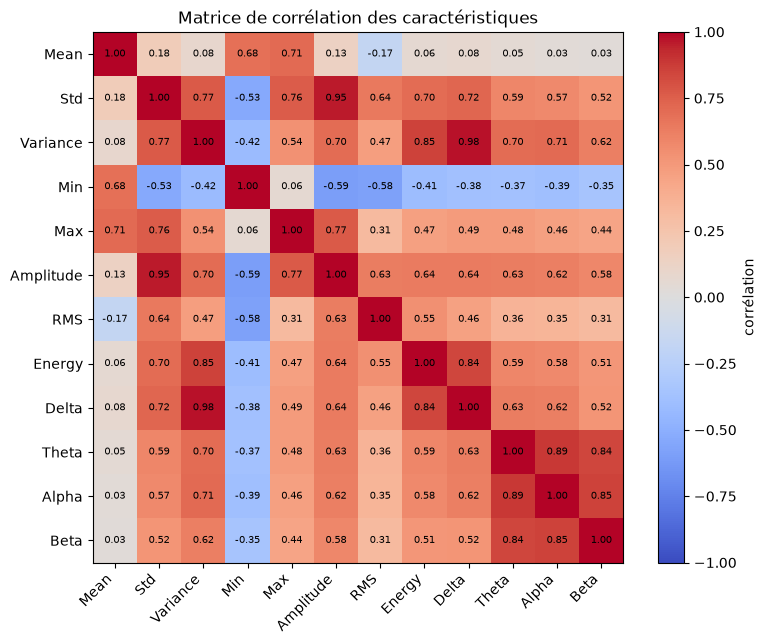

In [28]:
corr = data[FEATURE_COLS].corr()          # correlation de Pearson
display(corr.round(2))

if plt is not None:
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(FEATURE_COLS))); ax.set_xticklabels(FEATURE_COLS, rotation=45, ha='right')
    ax.set_yticks(range(len(FEATURE_COLS))); ax.set_yticklabels(FEATURE_COLS)
    for i in range(len(FEATURE_COLS)):
        for j in range(len(FEATURE_COLS)):
            ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
    fig.colorbar(im, ax=ax, label='corrélation'); ax.set_title('Matrice de corrélation des caractéristiques')
    plt.tight_layout(); plt.show()

In [29]:
from sklearn.metrics import roc_auc_score

# 1) et 2) : paires fortement correlees (|r| >= 0.9) -> informations redondantes
THRESHOLD = 0.90
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURE_COLS) for b in FEATURE_COLS[i + 1:] if abs(corr.loc[a, b]) >= THRESHOLD]
pairs = sorted(pairs, key=lambda p: -abs(p[2]))
print(f'Q11.1 - Paires fortement correlees (|r| >= {THRESHOLD}) : {len(pairs)}')
for a, b, r in pairs:
    print(f'   {a:<10} <-> {b:<10} r = {r:+.3f}')
print('Q11.2 - Ces paires apportent en grande partie la meme information (redondance). '
      'Certaines le sont par construction : Variance = Std², Amplitude = Max − Min, Energy = N × RMS².')

# 3) : pouvoir discriminant = AUC de chaque variable seule (0.5 = inutile, 1 = parfait) et ecart standardise entre classes
y_all = data['Class'].to_numpy()
rows = []
for col in FEATURE_COLS:
    auc = roc_auc_score(y_all, data[col].to_numpy())
    pooled = np.sqrt((data.loc[data['Class'] == 0, col].var() + data.loc[data['Class'] == 1, col].var()) / 2)
    d = (data.loc[data['Class'] == 1, col].mean() - data.loc[data['Class'] == 0, col].mean()) / pooled if pooled > 0 else np.nan
    rows.append({'caracteristique': col, 'AUC': auc, 'pouvoir_discriminant (|AUC-0.5|*2)': abs(auc - 0.5) * 2, 'ecart_standardise_d': d})
discrimination = pd.DataFrame(rows).sort_values('pouvoir_discriminant (|AUC-0.5|*2)', ascending=False).reset_index(drop=True)
print('\nQ11.3 - Caracteristiques classees par pouvoir discriminant :')
display(discrimination)
print('Les plus discriminantes :', ', '.join(discrimination['caracteristique'].head(3)))

Q11.1 - Paires fortement correlees (|r| >= 0.9) : 2
   Variance   <-> Delta      r = +0.976
   Std        <-> Amplitude  r = +0.954
Q11.2 - Ces paires apportent en grande partie la meme information (redondance). Certaines le sont par construction : Variance = Std², Amplitude = Max − Min, Energy = N × RMS².

Q11.3 - Caracteristiques classees par pouvoir discriminant :


,caracteristique,AUC,pouvoir_discriminant (|AUC-0.5|*2),ecart_standardise_d
0,Alpha,0.853092,0.706185,-0.053570
1,Theta,0.851827,0.703655,-0.063514
2,Amplitude,0.824711,0.649422,0.514060
3,Beta,0.807019,0.614039,-0.051892
4,Delta,0.783329,0.566657,-0.074346
5,Std,0.759646,0.519292,0.342976
6,Min,0.248687,0.502625,-0.727719
7,Variance,0.700417,0.400835,-0.088075
8,RMS,0.618016,0.236032,0.299313
9,Mean,0.411619,0.176763,-0.401451


Les plus discriminantes : Alpha, Theta, Amplitude


### Réponse à la question 11

1. **Caractéristiques fortement corrélées** : listées dans la cellule ci-dessus (paires avec |r| ≥ 0,9).
2. **Redondance** : oui, plusieurs caractéristiques portent la même information. Par définition, `Variance` = `Std`², `Amplitude` = `Max` − `Min` et `Energy` = N × `RMS`². Garder toutes ces variables n'apporte presque rien de plus aux modèles ; on pourra en supprimer certaines en partie XII (sélection de caractéristiques).
3. **Caractéristiques les plus discriminantes** : classées par AUC univariée (0,5 = aucune séparation, 1 = séparation parfaite) et par écart standardisé entre classes. Les premières lignes du tableau sont celles à retenir et à commenter dans le rapport.

# PARTIE VIII - Construction du modèle de Data Mining

Séparation des données en **80 % entraînement / 20 % test**, de manière **stratifiée** (même proportion de fenêtres de crise dans les deux jeux).

## Question 12 - Quatre modèles
Decision Tree, Random Forest, K-Nearest Neighbors, SVM. KNN et SVM sont sensibles à l'échelle des variables : ils sont donc précédés d'une standardisation (`StandardScaler`) dans un `Pipeline`, ajustée uniquement sur le jeu d'entraînement. Les modèles de base n'utilisent pas encore de traitement du déséquilibre (c'est une amélioration de la partie XII).

In [30]:
import time
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
X = features_freq[FEATURE_COLS]
y = features_freq['Class'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
split_report = pd.DataFrame({
    'jeu': ['entrainement', 'test'],
    'nb_fenetres': [len(y_train), len(y_test)],
    'nb_classe_1': [int(y_train.sum()), int(y_test.sum())],
    'pct_classe_1': [y_train.mean() * 100, y_test.mean() * 100],
})
display(split_report)

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)),
}

# Le SVM a noyau RBF devient tres lent au-dela de quelques dizaines de milliers d'exemples :
# on l'entraine alors sur un sous-echantillon stratifie du jeu d'entrainement (le test reste complet).
MAX_SVM_TRAIN = 30000
fitted, train_times = {}, {}
for name, model in models.items():
    Xt, yt = X_train, y_train
    if name == 'SVM' and len(X_train) > MAX_SVM_TRAIN:
        Xt, _, yt, _ = train_test_split(X_train, y_train, train_size=MAX_SVM_TRAIN, stratify=y_train, random_state=RANDOM_STATE)
        print(f'SVM : entrainement sur un sous-echantillon stratifie de {len(Xt)} fenetres (sur {len(X_train)}).')
    start = time.time()
    fitted[name] = model.fit(Xt, yt)
    train_times[name] = time.time() - start
    print(f'{name:<14} entraine en {train_times[name]:.1f} s')

,jeu,nb_fenetres,nb_classe_1,pct_classe_1
0,entrainement,26564,934,3.516037
1,test,6642,234,3.523035


Decision Tree  entraine en 0.7 s
Random Forest  entraine en 7.6 s
KNN            entraine en 0.2 s
SVM            entraine en 5.8 s


### Réponse à la question 12

Les quatre modèles sont entraînés sur 80 % des fenêtres. Le tableau ci-dessus vérifie que la **stratification** conserve la même proportion de fenêtres de crise dans l'entraînement et dans le test.

**Limite à signaler dans le rapport** : les fenêtres se chevauchent à 50 %. Avec une séparation aléatoire des fenêtres, une fenêtre de test a donc souvent une « voisine » presque identique dans l'entraînement, ce qui peut rendre les scores optimistes. La cellule de robustesse en fin de partie IX refait l'évaluation en séparant par patient.

# PARTIE IX - Évaluation des modèles

Pour chaque modèle : Accuracy, Precision, Recall, F1-score et matrice de confusion. Precision, Recall et F1 sont calculés pour la **classe 1 (crise)**, qui est la classe d'intérêt.

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

predictions, results, confusions = {}, [], {}
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    confusions[name] = confusion_matrix(y_test, y_pred, labels=[0, 1])
    results.append({'Modèle': name,
                    'Accuracy': accuracy_score(y_test, y_pred),
                    'Precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
                    'Recall': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
                    'F1-score': f1_score(y_test, y_pred, pos_label=1, zero_division=0)})
results_table = pd.DataFrame(results).set_index('Modèle')
results_table.round(4).to_csv(OUTPUT_DIR / 'resultats_modeles.csv')
display(results_table.round(4))

best_model_name = results_table['F1-score'].idxmax()      # meilleur modele selon le F1 de la classe crise
print('Meilleur modele (F1-score de la classe crise) :', best_model_name)

,Accuracy,Precision,Recall,F1-score
Modèle,,,,
Decision Tree,0.9714,0.5973,0.5769,0.5870
Random Forest,0.9795,0.8101,0.5470,0.6531
KNN,0.9746,0.6484,0.6068,0.6269
SVM,0.9648,0.0000,0.0000,0.0000


Meilleur modele (F1-score de la classe crise) : Random Forest


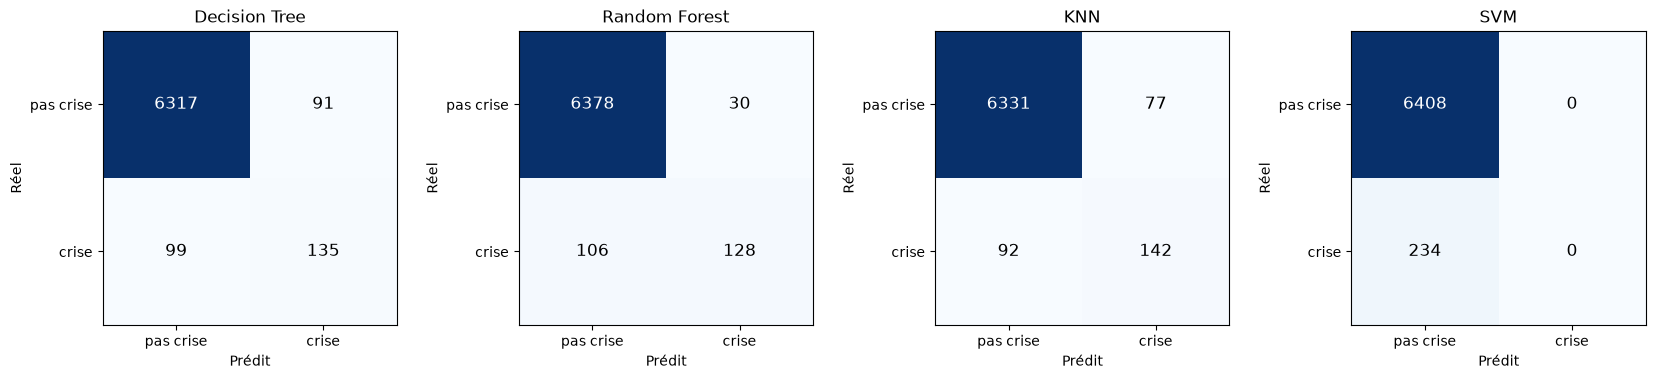

Decision Tree  vrais negatifs = 6317 | faux positifs = 91 | faux negatifs = 99 | vrais positifs = 135
Random Forest  vrais negatifs = 6378 | faux positifs = 30 | faux negatifs = 106 | vrais positifs = 128
KNN            vrais negatifs = 6331 | faux positifs = 77 | faux negatifs = 92 | vrais positifs = 142
SVM            vrais negatifs = 6408 | faux positifs = 0 | faux negatifs = 234 | vrais positifs = 0


In [32]:
if plt is not None:
    fig, axes = plt.subplots(1, len(confusions), figsize=(4.2 * len(confusions), 3.8))
    for ax, (name, cm) in zip(np.atleast_1d(axes), confusions.items()):
        ax.imshow(cm, cmap='Blues')
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', fontsize=12,
                        color='white' if cm[i, j] > cm.max() / 2 else 'black')
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(['pas crise', 'crise']); ax.set_yticklabels(['pas crise', 'crise'])
        ax.set(xlabel='Prédit', ylabel='Réel', title=name)
    plt.tight_layout(); plt.show()

# Lecture de la matrice : lignes = realite, colonnes = prediction
for name, cm in confusions.items():
    tn, fp, fn, tp = cm.ravel()
    print(f'{name:<14} vrais negatifs = {tn} | faux positifs = {fp} | faux negatifs = {fn} | vrais positifs = {tp}')

### Lecture de la matrice de confusion

- **Vrais négatifs (VN)** : fenêtres sans crise, prédites sans crise.
- **Faux positifs (FP)** : fenêtres sans crise, prédites « crise » (fausse alarme).
- **Faux négatifs (FN)** : fenêtres de crise, prédites « pas de crise » (crise manquée).
- **Vrais positifs (VP)** : fenêtres de crise, correctement détectées.

Precision = VP / (VP + FP) ; Recall = VP / (VP + FN) ; F1 = moyenne harmonique de Precision et Recall.

## Question 13 - Quelle métrique privilégier ?

Si 95 % des fenêtres sont « pas de crise », un modèle qui répond toujours « pas de crise » obtient 95 % d'Accuracy sans détecter aucune crise. La cellule suivante le vérifie sur nos données.

In [33]:
# Modele "naif" : predit toujours 0 (absence de crise)
y_naive = np.zeros(len(y_test), dtype=int)
naive = {'Accuracy': accuracy_score(y_test, y_naive),
         'Precision': precision_score(y_test, y_naive, pos_label=1, zero_division=0),
         'Recall': recall_score(y_test, y_naive, pos_label=1, zero_division=0),
         'F1-score': f1_score(y_test, y_naive, pos_label=1, zero_division=0)}
compare = pd.concat([results_table, pd.DataFrame(naive, index=['Toujours « pas de crise »'])])
compare.index.name = 'Modèle'
display(compare.round(4))
print(f"Part de fenetres sans crise dans le test : {(y_test == 0).mean() * 100:.2f} %")
print(f"Le modele naif obtient {naive['Accuracy'] * 100:.2f} % d'Accuracy avec un Recall de {naive['Recall']:.2f} : il ne detecte aucune crise.")

,Accuracy,Precision,Recall,F1-score
Modèle,,,,
Decision Tree,0.9714,0.5973,0.5769,0.5870
Random Forest,0.9795,0.8101,0.5470,0.6531
KNN,0.9746,0.6484,0.6068,0.6269
SVM,0.9648,0.0000,0.0000,0.0000
Toujours « pas de crise »,0.9648,0.0000,0.0000,0.0000


Part de fenetres sans crise dans le test : 96.48 %
Le modele naif obtient 96.48 % d'Accuracy avec un Recall de 0.00 : il ne detecte aucune crise.


### Réponse à la question 13

- **Accuracy** : proportion de bonnes prédictions toutes classes confondues. Avec des classes très déséquilibrées, elle est dominée par la classe majoritaire : le modèle « toujours pas de crise » a une Accuracy élevée et une utilité nulle. Elle est donc **trompeuse** ici.
- **Precision** : parmi les fenêtres prédites « crise », combien le sont vraiment. Elle mesure les fausses alarmes.
- **Recall** (sensibilité) : parmi les vraies crises, combien sont détectées. C'est la métrique **la plus importante** pour une application médicale, car une crise manquée (faux négatif) est plus grave qu'une fausse alarme.
- **F1-score** : moyenne harmonique de Precision et Recall. Il ne peut être élevé que si les deux le sont, ce qui en fait la **métrique de synthèse la plus pertinente** pour comparer les modèles sur la classe minoritaire.

**Conclusion** : on privilégie le **Recall** (ne pas rater de crises) et le **F1-score** (compromis avec la Precision), calculés sur la classe 1. L'Accuracy ne sert que de contrôle complémentaire. Le meilleur modèle retenu pour la suite (partie X) est celui qui a le meilleur F1-score, tout en vérifiant que son Recall est satisfaisant.

## Contrôle de robustesse (complément) : séparation par patient

Pour vérifier que les scores ne sont pas gonflés par les fenêtres voisines (recouvrement de 50 %), on réentraîne le meilleur modèle en gardant des **patients entiers** dans le jeu de test. Si les scores baissent nettement par rapport au tableau précédent, le modèle généralise moins bien à de nouveaux patients : à discuter dans le rapport.

In [34]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone

groups = features_freq['patient_id'].to_numpy()
if len(np.unique(groups)) >= 5:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    tr_idx, te_idx = next(splitter.split(X, y, groups))
    if y.iloc[te_idx].nunique() < 2 or y.iloc[tr_idx].nunique() < 2:
        print('Le test par patient ne contient qu une classe : changer random_state.')
    else:
        model = clone(models[best_model_name])
        Xt, yt = X.iloc[tr_idx], y.iloc[tr_idx]
        if best_model_name == 'SVM' and len(Xt) > MAX_SVM_TRAIN:
            Xt, _, yt, _ = train_test_split(Xt, yt, train_size=MAX_SVM_TRAIN, stratify=yt, random_state=RANDOM_STATE)
        model.fit(Xt, yt)
        yp = model.predict(X.iloc[te_idx])
        yt_test = y.iloc[te_idx]
        robust = pd.Series({'Accuracy': accuracy_score(yt_test, yp),
                            'Precision': precision_score(yt_test, yp, pos_label=1, zero_division=0),
                            'Recall': recall_score(yt_test, yp, pos_label=1, zero_division=0),
                            'F1-score': f1_score(yt_test, yp, pos_label=1, zero_division=0)}, name=f'{best_model_name} (test par patient)')
        display(pd.concat([results_table.loc[[best_model_name]].rename(index=lambda s: f'{s} (séparation aléatoire)'), robust.to_frame().T]).round(4))
        print('Patients en test :', sorted(set(groups[te_idx])))
else:
    print('Pas assez de patients pour une separation par patient.')

,Accuracy,Precision,Recall,F1-score
Random Forest (séparation aléatoire),0.9795,0.8101,0.5470,0.6531
Random Forest (test par patient),0.9743,0.8000,0.2939,0.4299


Patients en test : ['190304A_E', '191113A_D', '210914B_A', '220121B_D', '230105B_H']


## Bilan des parties VI à IX

- Partie VI : FFT par fenêtre, puissances Delta / Theta / Alpha / Beta ajoutées au dataset (`window_features_freq.csv`).
- Partie VII : comparaison des caractéristiques entre classes, matrice de corrélation, redondances et caractéristiques discriminantes.
- Partie VIII : séparation stratifiée 80 / 20 et entraînement de Decision Tree, Random Forest, KNN et SVM.
- Partie IX : Accuracy, Precision, Recall, F1 et matrices de confusion (`resultats_modeles.csv`), discussion de la métrique à privilégier, contrôle par patient.
- Suite : partie X (détection temporelle des crises avec `best_model_name`), partie XI (analyse des erreurs), partie XII (améliorations).

# PARTIE X - Détection temporelle des crises

Jusqu'ici le modèle prédit une classe pour chaque fenêtre. On reconstruit maintenant les crises **dans le temps** : des fenêtres consécutives prédites « crise » forment un intervalle `[début, fin]`.

**Choix important.** Avec la séparation aléatoire 80/20 de la partie VIII, les fenêtres de test sont dispersées au hasard dans le signal : on ne peut pas en tirer un intervalle continu. On utilise donc une **séparation par patient** (comme dans le contrôle de robustesse de la partie IX) : le modèle est entraîné sur certains patients, puis prédit **toutes les fenêtres** des patients de test, jamais vus à l'entraînement. C'est aussi l'évaluation la plus honnête.

In [35]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Rechargement defensif si la cellule est executee seule.
try:
    features_freq
except NameError:
    features_freq = pd.read_csv(OUTPUT_DIR / 'window_features_freq.csv')

FEATURE_COLS = ['Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS',
                'Energy', 'Delta', 'Theta', 'Alpha', 'Beta']
RANDOM_STATE = globals().get('RANDOM_STATE', 42)
MAX_SVM_TRAIN = globals().get('MAX_SVM_TRAIN', 30000)

try:
    models
except NameError:
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC
    models = {
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)),
    }

if 'best_model_name' not in globals():
    result_path = OUTPUT_DIR / 'resultats_modeles.csv'
    if result_path.exists():
        best_model_name = pd.read_csv(result_path, index_col=0)['F1-score'].idxmax()
    else:
        best_model_name = 'Random Forest'

X_all = features_freq[FEATURE_COLS]
y_all = features_freq['Class'].astype(int)
groups_all = features_freq['patient_id'].astype(str).to_numpy()

def choose_group_split(X, y, groups, max_tries=200):
    """Choisit une separation par patient avec les deux classes dans train et test."""
    for seed in range(RANDOM_STATE, RANDOM_STATE + max_tries):
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=seed)
        train_idx, test_idx = next(splitter.split(X, y, groups))
        if y.iloc[train_idx].nunique() == 2 and y.iloc[test_idx].nunique() == 2:
            return train_idx, test_idx, seed
    raise ValueError('Impossible de trouver une separation par patient contenant les deux classes.')

train_idx, test_idx, split_seed = choose_group_split(X_all, y_all, groups_all)
temporal_model = clone(models[best_model_name])

X_temporal_train, y_temporal_train = X_all.iloc[train_idx], y_all.iloc[train_idx]
if best_model_name == 'SVM' and len(X_temporal_train) > MAX_SVM_TRAIN:
    X_temporal_train, _, y_temporal_train, _ = train_test_split(
        X_temporal_train, y_temporal_train,
        train_size=MAX_SVM_TRAIN,
        stratify=y_temporal_train,
        random_state=RANDOM_STATE,
    )

temporal_model.fit(X_temporal_train, y_temporal_train)
temporal_predictions = features_freq.iloc[test_idx].copy()
temporal_predictions['prediction'] = temporal_model.predict(X_all.iloc[test_idx]).astype(int)
temporal_predictions['split_seed'] = split_seed
temporal_predictions['modele'] = best_model_name
temporal_predictions = temporal_predictions.sort_values(['patient_id', 'window_start']).reset_index(drop=True)

def predicted_intervals_from_windows(frame, pred_col='prediction'):
    rows = []
    for patient, group in frame.sort_values(['patient_id', 'window_start']).groupby('patient_id'):
        run = None
        n_windows = 0
        for row in group.itertuples(index=False):
            is_positive = int(getattr(row, pred_col)) == 1
            if is_positive and run is None:
                run = [patient, float(row.window_start), float(row.window_end)]
                n_windows = 1
            elif is_positive:
                run[2] = float(row.window_end)
                n_windows += 1
            elif run is not None:
                rows.append({'patient_id': run[0], 'pred_start': run[1], 'pred_end': run[2],
                             'pred_duration': run[2] - run[1], 'nb_fenetres': n_windows})
                run = None
                n_windows = 0
        if run is not None:
            rows.append({'patient_id': run[0], 'pred_start': run[1], 'pred_end': run[2],
                         'pred_duration': run[2] - run[1], 'nb_fenetres': n_windows})
    return pd.DataFrame(rows)

detected_intervals = predicted_intervals_from_windows(temporal_predictions)
detected_intervals.to_csv(OUTPUT_DIR / 'partie_X_crises_detectees.csv', index=False)

display(detected_intervals.head(20))
print('Modele utilise pour la detection temporelle :', best_model_name)
print('Graine de separation par patient :', split_seed)
print('Patients de test :', ', '.join(sorted(temporal_predictions['patient_id'].unique())))
print('Nombre de crises detectees :', len(detected_intervals))


,patient_id,pred_start,pred_end,pred_duration,nb_fenetres
0,190304A_E,1291.0,1293.996094,2.996094,2
1,210914B_A,14.0,15.996094,1.996094,1
2,210914B_A,17.0,18.996094,1.996094,1
3,210914B_A,30.0,32.996094,2.996094,2
4,210914B_A,39.0,41.996094,2.996094,2
5,210914B_A,44.0,45.996094,1.996094,1
6,210914B_A,64.0,66.996094,2.996094,2
7,210914B_A,81.0,82.996094,1.996094,1
8,210914B_A,83.0,84.996094,1.996094,1
9,210914B_A,104.0,105.996094,1.996094,1


Modele utilise pour la detection temporelle : Random Forest
Graine de separation par patient : 42
Patients de test : 190304A_E, 191113A_D, 210914B_A, 220121B_D, 230105B_H
Nombre de crises detectees : 57


In [36]:
try:
    annotations_with_signals
except NameError:
    annotations_with_signals = pd.read_csv(OUTPUT_DIR / 'annotations_with_signals.csv')

true_intervals = annotations_with_signals.loc[
    annotations_with_signals['annotation_valid'].astype(bool) &
    annotations_with_signals['patient_id_signal'].isin(temporal_predictions['patient_id'].unique()),
    ['patient_id_signal', 'crise', 'start_seconds', 'end_seconds', 'duration_seconds']
].rename(columns={'patient_id_signal': 'patient_id'}).reset_index(drop=True)

def overlap_seconds(a_start, a_end, b_start, b_end):
    return max(0.0, min(float(a_end), float(b_end)) - max(float(a_start), float(b_start)))

matches = []
matched_true = set()
for pred_id, pred in detected_intervals.reset_index().rename(columns={'index': 'pred_id'}).iterrows():
    candidates = true_intervals[true_intervals['patient_id'] == pred['patient_id']]
    best = None
    for true_id, true in candidates.iterrows():
        ov = overlap_seconds(pred['pred_start'], pred['pred_end'], true['start_seconds'], true['end_seconds'])
        union = max(pred['pred_end'], true['end_seconds']) - min(pred['pred_start'], true['start_seconds'])
        iou = ov / union if union > 0 else 0.0
        if best is None or ov > best['overlap_seconds']:
            best = {'true_id': true_id, 'crise': int(true['crise']), 'true_start': true['start_seconds'],
                    'true_end': true['end_seconds'], 'overlap_seconds': ov, 'iou': iou}
    if best is not None and best['overlap_seconds'] > 0:
        matched_true.add(best['true_id'])
        status = 'vrai_positif'
    else:
        best = {'true_id': np.nan, 'crise': np.nan, 'true_start': np.nan, 'true_end': np.nan,
                'overlap_seconds': 0.0, 'iou': 0.0}
        status = 'faux_positif'
    matches.append({**pred.to_dict(), **best, 'statut_intervalle': status})

interval_comparison = pd.DataFrame(matches)
false_negatives = true_intervals.loc[~true_intervals.index.isin(matched_true)].copy()
false_negatives['pred_start'] = np.nan
false_negatives['pred_end'] = np.nan
false_negatives['pred_duration'] = np.nan
false_negatives['nb_fenetres'] = 0
false_negatives['true_id'] = false_negatives.index
false_negatives['true_start'] = false_negatives['start_seconds']
false_negatives['true_end'] = false_negatives['end_seconds']
false_negatives['overlap_seconds'] = 0.0
false_negatives['iou'] = 0.0
false_negatives['statut_intervalle'] = 'faux_negatif'

interval_errors = pd.concat([
    interval_comparison,
    false_negatives[['patient_id', 'pred_start', 'pred_end', 'pred_duration', 'nb_fenetres',
                     'true_id', 'crise', 'true_start', 'true_end',
                     'overlap_seconds', 'iou', 'statut_intervalle']]
], ignore_index=True, sort=False)

interval_errors.to_csv(OUTPUT_DIR / 'partie_X_comparaison_intervalles.csv', index=False)
display(interval_errors.sort_values(['patient_id', 'true_start', 'pred_start']).head(30))

vp = int((interval_errors['statut_intervalle'] == 'vrai_positif').sum())
fp = int((interval_errors['statut_intervalle'] == 'faux_positif').sum())
fn = int((interval_errors['statut_intervalle'] == 'faux_negatif').sum())
precision_intervalle = vp / (vp + fp) if (vp + fp) else 0.0
rappel_intervalle = vp / (vp + fn) if (vp + fn) else 0.0
f1_intervalle = 2 * precision_intervalle * rappel_intervalle / (precision_intervalle + rappel_intervalle) if (precision_intervalle + rappel_intervalle) else 0.0
interval_metrics = pd.DataFrame([{
    'modele': best_model_name,
    'patients_test': ', '.join(sorted(temporal_predictions['patient_id'].unique())),
    'vrais_positifs': vp,
    'faux_positifs': fp,
    'faux_negatifs': fn,
    'precision_intervalle': precision_intervalle,
    'rappel_intervalle': rappel_intervalle,
    'f1_intervalle': f1_intervalle,
}])
interval_metrics.to_csv(OUTPUT_DIR / 'partie_X_metriques_intervalles.csv', index=False)
display(interval_metrics)


,pred_id,patient_id,pred_start,pred_end,pred_duration,nb_fenetres,true_id,crise,true_start,true_end,overlap_seconds,iou,statut_intervalle
0,0.0,190304A_E,1291.0,1293.996094,2.996094,2,0.0,1.0,1291.0,1298.0,2.996094,0.428013,vrai_positif
57,NaN,191113A_D,NaN,NaN,NaN,0,1.0,1.0,1254.0,1267.0,0.000000,0.000000,faux_negatif
58,NaN,191113A_D,NaN,NaN,NaN,0,2.0,2.0,1428.0,1433.0,0.000000,0.000000,faux_negatif
1,1.0,210914B_A,14.0,15.996094,1.996094,1,3.0,1.0,14.0,18.0,1.996094,0.499023,vrai_positif
2,2.0,210914B_A,17.0,18.996094,1.996094,1,3.0,1.0,14.0,18.0,1.000000,0.200156,vrai_positif
3,3.0,210914B_A,30.0,32.996094,2.996094,2,4.0,2.0,28.0,66.0,2.996094,0.078845,vrai_positif
4,4.0,210914B_A,39.0,41.996094,2.996094,2,4.0,2.0,28.0,66.0,2.996094,0.078845,vrai_positif
5,5.0,210914B_A,44.0,45.996094,1.996094,1,4.0,2.0,28.0,66.0,1.996094,0.052529,vrai_positif
6,6.0,210914B_A,64.0,66.996094,2.996094,2,4.0,2.0,28.0,66.0,2.000000,0.051287,vrai_positif
7,7.0,210914B_A,81.0,82.996094,1.996094,1,5.0,3.0,81.0,87.0,1.996094,0.332682,vrai_positif


,modele,patients_test,vrais_positifs,faux_positifs,faux_negatifs,precision_intervalle,rappel_intervalle,f1_intervalle
0,Random Forest,"190304A_E, 191113A_D, 210914B_A, 220121B_D, 23...",39,18,3,0.684211,0.928571,0.787879


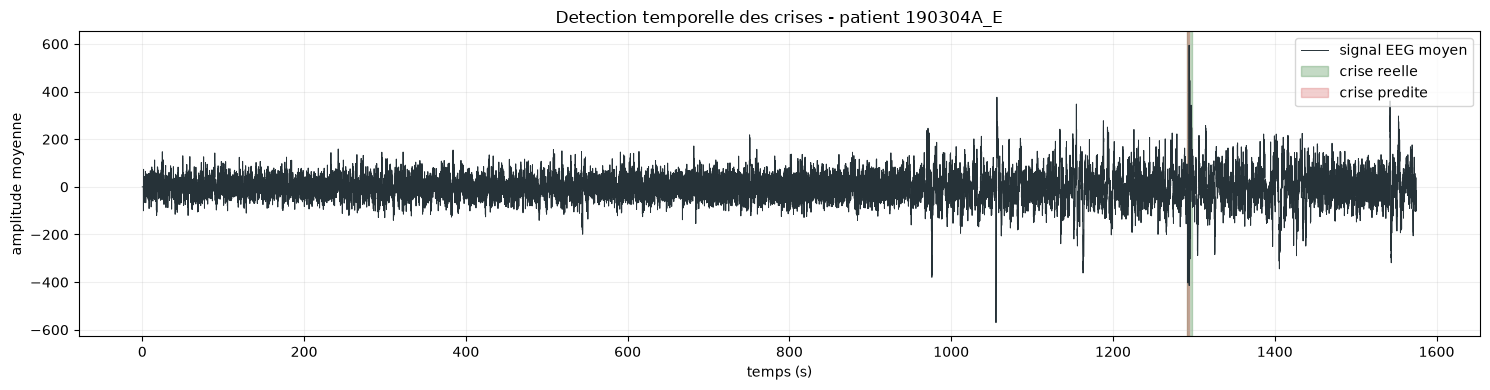

In [37]:
if plt is not None and len(temporal_predictions):
    patients_with_events = interval_errors.loc[
        interval_errors['statut_intervalle'].isin(['vrai_positif', 'faux_negatif']),
        'patient_id'
    ].dropna().astype(str)
    patient_to_plot = patients_with_events.iloc[0] if len(patients_with_events) else temporal_predictions['patient_id'].iloc[0]
    csv_path = CSV_DIR / f'{patient_to_plot}_0000d.csv'
    if csv_path.exists():
        signal = pd.read_csv(csv_path)
        channels = [c for c in signal.columns if c.startswith('channel_')]
        y_plot = signal[channels[:min(3, len(channels))]].mean(axis=1)
        step = max(1, len(signal) // 12000)
        fig, ax = plt.subplots(figsize=(15, 4))
        ax.plot(signal['time'].iloc[::step], y_plot.iloc[::step], color='#263238', linewidth=.7, label='signal EEG moyen')
        for _, row in true_intervals[true_intervals['patient_id'] == patient_to_plot].iterrows():
            ax.axvspan(row['start_seconds'], row['end_seconds'], color='#2e7d32', alpha=.28,
                       label='crise reelle' if 'crise reelle' not in ax.get_legend_handles_labels()[1] else None)
        for _, row in detected_intervals[detected_intervals['patient_id'] == patient_to_plot].iterrows():
            ax.axvspan(row['pred_start'], row['pred_end'], color='#c62828', alpha=.22,
                       label='crise predite' if 'crise predite' not in ax.get_legend_handles_labels()[1] else None)
        ax.set(title=f'Detection temporelle des crises - patient {patient_to_plot}',
               xlabel='temps (s)', ylabel='amplitude moyenne')
        ax.grid(alpha=.2)
        ax.legend(loc='upper right')
        plt.tight_layout()
        plt.show()
    else:
        print('CSV signal introuvable pour', patient_to_plot)
else:
    print('Graphique non genere.')


### Reponse a la question 14

La detection temporelle est reconstruite a partir des fenetres consecutives predites en classe 1 par le meilleur modele. Chaque groupe de fenetres positives devient un intervalle `[debut, fin]`, exporte dans `partie_X_crises_detectees.csv`.

La comparaison avec les annotations reelles est faite patient par patient. Un intervalle predit est compte comme **vrai positif** s'il recouvre au moins une crise annotee. S'il ne recouvre aucune annotation, c'est un **faux positif**. Une crise annotee sans intervalle predit correspondant est un **faux negatif**. Les exports `partie_X_comparaison_intervalles.csv` et `partie_X_metriques_intervalles.csv` donnent les intervalles, les recouvrements et les scores temporels.


# PARTIE XI - Analyse des erreurs

On analyse les erreurs du meilleur modele a deux niveaux :

- **niveau fenetre** : chaque fenetre de test est classee en vrai negatif, faux positif, faux negatif ou vrai positif ;
- **niveau crise** : les intervalles reconstruits sont compares aux annotations reelles.


In [38]:
cm_temporal = confusion_matrix(temporal_predictions['Class'], temporal_predictions['prediction'], labels=[0, 1])
tn, fp_w, fn_w, tp_w = cm_temporal.ravel()
window_error_summary = pd.DataFrame([
    {'type': 'vrai_negatif', 'nombre': tn},
    {'type': 'faux_positif', 'nombre': fp_w},
    {'type': 'faux_negatif', 'nombre': fn_w},
    {'type': 'vrai_positif', 'nombre': tp_w},
])

temporal_predictions['type_erreur'] = np.select(
    [
        (temporal_predictions['Class'] == 0) & (temporal_predictions['prediction'] == 0),
        (temporal_predictions['Class'] == 0) & (temporal_predictions['prediction'] == 1),
        (temporal_predictions['Class'] == 1) & (temporal_predictions['prediction'] == 0),
        (temporal_predictions['Class'] == 1) & (temporal_predictions['prediction'] == 1),
    ],
    ['vrai_negatif', 'faux_positif', 'faux_negatif', 'vrai_positif'],
    default='inconnu',
)

window_error_by_patient = temporal_predictions.pivot_table(
    index='patient_id',
    columns='type_erreur',
    values='Window',
    aggfunc='count',
    fill_value=0,
).reset_index()

temporal_predictions.to_csv(OUTPUT_DIR / 'partie_XI_predictions_fenetres.csv', index=False)
window_error_summary.to_csv(OUTPUT_DIR / 'partie_XI_resume_erreurs_fenetres.csv', index=False)
window_error_by_patient.to_csv(OUTPUT_DIR / 'partie_XI_erreurs_par_patient.csv', index=False)

display(window_error_summary)
display(window_error_by_patient)
print(f'Precision fenetre classe crise : {precision_score(temporal_predictions["Class"], temporal_predictions["prediction"], pos_label=1, zero_division=0):.3f}')
print(f'Recall fenetre classe crise    : {recall_score(temporal_predictions["Class"], temporal_predictions["prediction"], pos_label=1, zero_division=0):.3f}')
print(f'F1-score fenetre classe crise  : {f1_score(temporal_predictions["Class"], temporal_predictions["prediction"], pos_label=1, zero_division=0):.3f}')


,type,nombre
0,vrai_negatif,9141
1,faux_positif,23
2,faux_negatif,221
3,vrai_positif,92


type_erreur,patient_id,faux_negatif,faux_positif,vrai_negatif,vrai_positif
0,190304A_E,6,0,1566,2
1,191113A_D,20,0,1789,0
2,210914B_A,151,3,1014,36
3,220121B_D,15,14,1224,38
4,230105B_H,29,6,3548,16


Precision fenetre classe crise : 0.800
Recall fenetre classe crise    : 0.294
F1-score fenetre classe crise  : 0.430


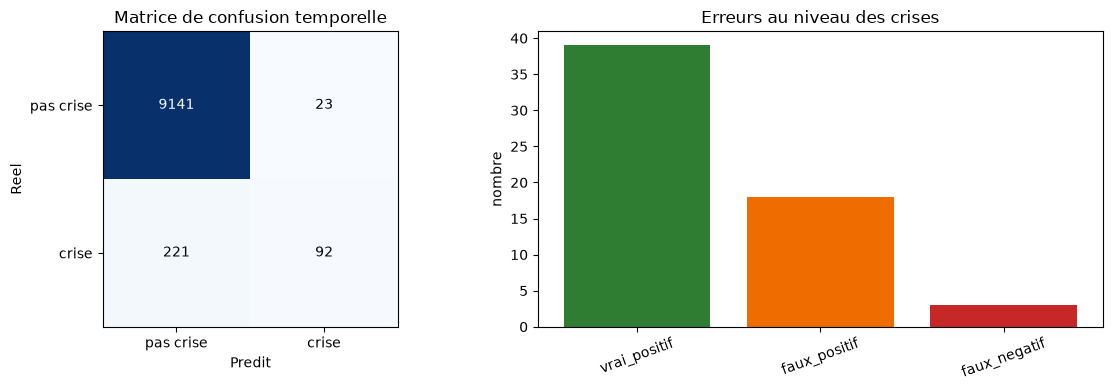

In [39]:
if plt is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(cm_temporal, cmap='Blues')
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, str(cm_temporal[i, j]), ha='center', va='center',
                         color='white' if cm_temporal[i, j] > cm_temporal.max() / 2 else 'black')
    axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
    axes[0].set_xticklabels(['pas crise', 'crise']); axes[0].set_yticklabels(['pas crise', 'crise'])
    axes[0].set(xlabel='Predit', ylabel='Reel', title='Matrice de confusion temporelle')

    interval_counts = interval_errors['statut_intervalle'].value_counts().reindex(
        ['vrai_positif', 'faux_positif', 'faux_negatif'], fill_value=0
    )
    axes[1].bar(interval_counts.index, interval_counts.values, color=['#2e7d32', '#ef6c00', '#c62828'])
    axes[1].set(title='Erreurs au niveau des crises', ylabel='nombre')
    axes[1].tick_params(axis='x', rotation=20)
    plt.tight_layout()
    plt.show()


### Reponse a la partie XI

Les erreurs se lisent de deux facons. Au niveau des fenetres, les **faux positifs** sont des fenetres hors crise classees a tort comme crise ; les **faux negatifs** sont des fenetres de crise ratees ; les **vrais positifs** sont les fenetres de crise correctement detectees ; les **vrais negatifs** sont les fenetres hors crise correctement rejetees.

Au niveau temporel, les faux positifs correspondent a des intervalles predits qui ne recouvrent aucune annotation reelle. Les faux negatifs correspondent a des crises annotees sans intervalle predit. Dans une application medicale, les faux negatifs sont les plus critiques, car ils signifient une crise manquee. Les faux positifs restent importants car ils augmentent les fausses alertes, mais ils sont en general moins graves qu'une absence de detection.

Les fichiers `partie_XI_predictions_fenetres.csv`, `partie_XI_resume_erreurs_fenetres.csv` et `partie_XI_erreurs_par_patient.csv` permettent de retrouver les erreurs et de les commenter dans le rapport.


# PARTIE XII - Amelioration du systeme

On travaille uniquement deux ameliorations demandees :

1. **traiter le desequilibre de classe** : les crises sont rares, donc un modele peut avoir une bonne Accuracy tout en ratant les crises ;
2. **utiliser le deep learning** : entrainer un reseau de neurones dense sur les caracteristiques deja extraites.

Les resultats sont compares aux modeles de la partie IX avec les memes donnees d'entrainement et de test.


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

# Rechargement defensif si la cellule est executee directement.
try:
    X_train, X_test, y_train, y_test, results_table
except NameError:
    from sklearn.model_selection import train_test_split
    features_freq = pd.read_csv(OUTPUT_DIR / 'window_features_freq.csv')
    FEATURE_COLS = ['Mean', 'Std', 'Variance', 'Min', 'Max', 'Amplitude', 'RMS',
                    'Energy', 'Delta', 'Theta', 'Alpha', 'Beta']
    X = features_freq[FEATURE_COLS]
    y = features_freq['Class'].astype(int)
    RANDOM_STATE = globals().get('RANDOM_STATE', 42)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
    result_path = OUTPUT_DIR / 'resultats_modeles.csv'
    results_table = pd.read_csv(result_path, index_col=0) if result_path.exists() else pd.DataFrame()

RANDOM_STATE = globals().get('RANDOM_STATE', 42)

class_balance_train = y_train.value_counts().sort_index().rename_axis('Class').reset_index(name='nombre')
class_balance_train['pourcentage'] = class_balance_train['nombre'] / len(y_train) * 100
display(class_balance_train)

# Amelioration 1 : ponderer les classes dans le Random Forest.
# La classe 1 etant minoritaire, class_weight='balanced_subsample' penalise plus fortement les crises ratees.
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced_subsample',
    min_samples_leaf=2,
)
rf_balanced.fit(X_train, y_train)
y_pred_rf_balanced = rf_balanced.predict(X_test)

balanced_rf_metrics = {
    'Modele': 'Random Forest equilibre',
    'Accuracy': accuracy_score(y_test, y_pred_rf_balanced),
    'Precision': precision_score(y_test, y_pred_rf_balanced, pos_label=1, zero_division=0),
    'Recall': recall_score(y_test, y_pred_rf_balanced, pos_label=1, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_rf_balanced, pos_label=1, zero_division=0),
}
display(pd.DataFrame([balanced_rf_metrics]).set_index('Modele').round(4))

cm_rf_balanced = confusion_matrix(y_test, y_pred_rf_balanced, labels=[0, 1])
print('Matrice de confusion Random Forest equilibre :')
print(cm_rf_balanced)


,Class,nombre,pourcentage
0,0,25630,96.483963
1,1,934,3.516037


,Accuracy,Precision,Recall,F1-score
Modele,,,,
Random Forest equilibre,0.9809,0.7801,0.6368,0.7012


Matrice de confusion Random Forest equilibre :
[[6366   42]
 [  85  149]]


In [41]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils import resample

# Amelioration 2 : deep learning leger sur les caracteristiques.
# On sur-echantillonne uniquement la classe minoritaire dans le jeu d'entrainement.
train_balanced = pd.concat([X_train.reset_index(drop=True), y_train.reset_index(drop=True).rename('Class')], axis=1)
majority = train_balanced[train_balanced['Class'] == 0]
minority = train_balanced[train_balanced['Class'] == 1]

minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=RANDOM_STATE,
)
train_deep = pd.concat([majority, minority_upsampled], ignore_index=True).sample(
    frac=1,
    random_state=RANDOM_STATE,
)

X_train_deep = train_deep.drop(columns='Class')
y_train_deep = train_deep['Class'].astype(int)

print('Distribution avant reequilibrage :')
print(y_train.value_counts().sort_index())
print('\nDistribution apres sur-echantillonnage :')
print(y_train_deep.value_counts().sort_index())

deep_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=120,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=RANDOM_STATE,
    ),
)

deep_model.fit(X_train_deep, y_train_deep)
y_pred_deep = deep_model.predict(X_test)

deep_metrics = {
    'Modele': 'Deep learning MLP reequilibre',
    'Accuracy': accuracy_score(y_test, y_pred_deep),
    'Precision': precision_score(y_test, y_pred_deep, pos_label=1, zero_division=0),
    'Recall': recall_score(y_test, y_pred_deep, pos_label=1, zero_division=0),
    'F1-score': f1_score(y_test, y_pred_deep, pos_label=1, zero_division=0),
}
display(pd.DataFrame([deep_metrics]).set_index('Modele').round(4))

cm_deep = confusion_matrix(y_test, y_pred_deep, labels=[0, 1])
print('Matrice de confusion Deep learning :')
print(cm_deep)


Distribution avant reequilibrage :
Class
0    25630
1      934
Name: count, dtype: int64

Distribution apres sur-echantillonnage :
Class
0    25630
1    25630
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-score
Modele,,,,
Deep learning MLP reequilibre,0.9213,0.2968,0.9017,0.4466


Matrice de confusion Deep learning :
[[5908  500]
 [  23  211]]


,Accuracy,Precision,Recall,F1-score
Decision Tree,0.9714,0.5973,0.5769,0.5870
Random Forest,0.9795,0.8101,0.5470,0.6531
KNN,0.9746,0.6484,0.6068,0.6269
SVM,0.9648,0.0000,0.0000,0.0000
Random Forest equilibre,0.9809,0.7801,0.6368,0.7012
Deep learning MLP reequilibre,0.9213,0.2968,0.9017,0.4466


Meilleur modele selon F1-score : Random Forest equilibre
Meilleur modele selon Recall   : Deep learning MLP reequilibre


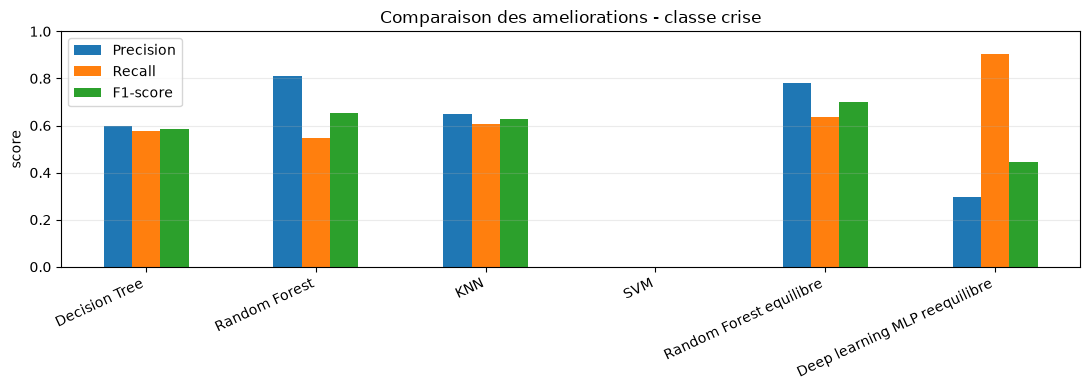

In [42]:
partie_xii_results = pd.DataFrame([balanced_rf_metrics, deep_metrics]).set_index('Modele')

if isinstance(results_table, pd.DataFrame) and len(results_table):
    comparison_xii = pd.concat([results_table, partie_xii_results], axis=0)
else:
    comparison_xii = partie_xii_results.copy()

comparison_xii = comparison_xii[['Accuracy', 'Precision', 'Recall', 'F1-score']]
comparison_xii.round(4).to_csv(OUTPUT_DIR / 'partie_XII_resultats_ameliorations.csv')
display(comparison_xii.round(4))

best_xii = comparison_xii['F1-score'].idxmax()
best_recall_xii = comparison_xii['Recall'].idxmax()
print('Meilleur modele selon F1-score :', best_xii)
print('Meilleur modele selon Recall   :', best_recall_xii)

if plt is not None:
    ax = comparison_xii[['Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(11, 4))
    ax.set_ylim(0, 1)
    ax.set_title('Comparaison des ameliorations - classe crise')
    ax.set_ylabel('score')
    ax.grid(alpha=.25, axis='y')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.show()


### Reponse a la partie XII

Deux ameliorations ont ete testees.

**1. Traiter le desequilibre de classe.** Les fenetres de crise sont minoritaires. Le Random Forest equilibre utilise `class_weight='balanced_subsample'`, ce qui donne plus de poids a la classe 1 pendant l'entrainement. L'objectif est surtout d'augmenter le **Recall** des crises, meme si cela peut diminuer la Precision en creant plus de fausses alertes.

**2. Utiliser le deep learning.** Un reseau de neurones dense de type MLP est entraine sur les 12 caracteristiques (`Mean`, `Std`, `Variance`, `Min`, `Max`, `Amplitude`, `RMS`, `Energy`, `Delta`, `Theta`, `Alpha`, `Beta`). Avant l'entrainement, la classe crise est sur-echantillonnee uniquement dans le jeu d'entrainement pour eviter que le reseau apprenne surtout la classe majoritaire.

La comparaison finale est enregistree dans `partie_XII_resultats_ameliorations.csv`. Pour conclure, on retient en priorite le modele qui garde un bon **Recall** et un bon **F1-score** sur la classe crise, car l'Accuracy seule reste trompeuse dans ce projet.
